<a href="https://colab.research.google.com/github/ajustogonzalez/Activ-2_ModeloFin/blob/main/Copia_de_Actividad_2__Master.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo Financiero Integral con IA para Apple Inc. - Notebook Completo Introducción

Este notebook desarrolla un modelo integral de predicción financiera que combina análisis de sentimiento, indicadores técnicos y datos fundamentales para predecir la dirección del precio de las acciones de Apple Inc. utilizando técnicas avanzadas de machine learning.

In [16]:
#  Importación de todas las librerías necesarias
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Machine Learning
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTE

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, GRU, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# NLP para análisis de sentimiento
from textblob import TextBlob
import nltk
nltk.download('vader_lexicon', quiet=True)
from nltk.sentiment import SentimentIntensityAnalyzer

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("🚀 Librerías importadas correctamente")
print(f"📅 Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"🔧 Versión de TensorFlow: {tf.__version__}")

🚀 Librerías importadas correctamente
📅 Fecha de ejecución: 2026-11-08 18:57:14
🔧 Versión de TensorFlow: 2.21.0


## 1. Recolección de Datos de Sentimiento


### Instalación de dependencias necesarias para Reddit y FinBERT
Instalamos `praw` para conectarnos a la API de Reddit y `transformers` de Hugging Face junto con `torch` para ejecutar el modelo de Deep Learning FinBERT.

In [17]:
!pip install praw transformers torch --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


### Configuración de la API de Reddit y Extracción de Datos
Configura tus credenciales de la API de Reddit en la siguiente celda. Extraeremos las publicaciones más recientes sobre Apple en subreddits financieros clave como `wallstreetbets`, `stocks`, e `investing`.

In [31]:
import sys
try:
    import praw
except ModuleNotFoundError:
    print("📦 Instalando 'praw' de manera dinámica...")
    !{sys.executable} -m pip install praw --quiet
    import praw

import pandas as pd
from datetime import datetime
from google.colab import userdata

try:
    # Intenta obtener las credenciales guardadas en los secretos de Colab
    REDDIT_CLIENT_ID = userdata.get('REDDIT_CLIENT_ID')
    REDDIT_CLIENT_SECRET = userdata.get('REDDIT_CLIENT_SECRET')
    REDDIT_USER_AGENT = userdata.get('REDDIT_USER_AGENT', 'MyColabFinAgent 1.0')
except Exception:
    # Valores por defecto para rellenar de forma manual si no se configuran secretos
    REDDIT_CLIENT_ID = 'TU_CLIENT_ID'
    REDDIT_CLIENT_SECRET = 'TU_CLIENT_SECRET'
    REDDIT_USER_AGENT = 'MyColabFinAgent 1.0'

def fetch_reddit_posts(query="Amazon AMZN", subreddits="wallstreetbets+stocks+investing", limit=200):
    """Extrae publicaciones de Reddit basadas en una consulta y subreddits."""
    if REDDIT_CLIENT_ID == 'TU_CLIENT_ID' or not REDDIT_CLIENT_ID:
        print("⚠️ Por favor, configura tus credenciales de Reddit API en los secretos o variables de Colab.")
        print("Simulando DataFrame vacío por falta de credenciales...")
        return pd.DataFrame(columns=['Date', 'Title', 'Score', 'Num_Comments'])

    reddit = praw.Reddit(
        client_id=REDDIT_CLIENT_ID,
        client_secret=REDDIT_CLIENT_SECRET,
        user_agent=REDDIT_USER_AGENT
    )

    posts_data = []
    try:
        for post in reddit.subreddit(subreddits).search(query, limit=limit, sort='new'):
            posts_data.append({
                'Date': datetime.fromtimestamp(post.created_utc).strftime('%Y-%m-%d'),
                'Title': post.title,
                'Score': post.score,
                'Num_Comments': post.num_comments
            })
        print(f"✅ Se han extraído {len(posts_data)} publicaciones exitosamente.")
    except Exception as e:
        print(f"❌ Error al conectar o extraer de Reddit: {e}")

    return pd.DataFrame(posts_data)

# Extraer publicaciones reales de Amazon
raw_reddit_df = fetch_reddit_posts()
if not raw_reddit_df.empty:
    display(raw_reddit_df.head())

⚠️ Por favor, configura tus credenciales de Reddit API en los secretos o variables de Colab.
Simulando DataFrame vacío por falta de credenciales...


### Procesamiento de Sentimiento Financiero con FinBERT
Utilizaremos la arquitectura pre-entrenada de Hugging Face `ProsusAI/finbert` para clasificar las publicaciones de Reddit en sentimientos financieros: positivo, negativo o neutral.

In [19]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch
import numpy as np

# Cargar el tokenizador y el modelo de FinBERT
print("🤖 Cargando modelo FinBERT (ProsusAI/finbert)... ")
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")

def analyze_sentiment_finbert(texts, batch_size=32):
    """Aplica el modelo FinBERT a una lista de textos para predecir probabilidades de sentimiento."""
    results = []
    # Usar GPU si está disponible para acelerar la inferencia
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()

    print(f"Calculando sentimiento en batches con dispositivo: {device}")
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.nn.functional.softmax(outputs.logits, dim=-1).cpu().numpy()

        # FinBERT retorna etiquetas en este orden exacto: [positive, negative, neutral]
        results.extend(probs)

    return np.array(results)

# Ejecutar análisis en los títulos recolectados de Reddit
if not raw_reddit_df.empty:
    titles = raw_reddit_df['Title'].tolist()
    sentiments = analyze_sentiment_finbert(titles)

    # Guardar resultados en el DataFrame
    raw_reddit_df['positive_sentiment'] = sentiments[:, 0]
    raw_reddit_df['negative_sentiment'] = sentiments[:, 1]
    raw_reddit_df['neutral_sentiment'] = sentiments[:, 2]
    raw_reddit_df['compound_sentiment'] = raw_reddit_df['positive_sentiment'] - raw_reddit_df['negative_sentiment']

    # Agrupar métricas diariamente
    reddit_sentiment_daily = raw_reddit_df.groupby('Date').agg({
        'positive_sentiment': 'mean',
        'negative_sentiment': 'mean',
        'neutral_sentiment': 'mean',
        'compound_sentiment': 'mean',
        'Score': 'sum', # Reemplaza el volumen simulado por interacciones reales de Reddit
        'Num_Comments': 'sum'
    }).reset_index()

    print("\n📊 Datos agregados diariamente con FinBERT:")
    display(reddit_sentiment_daily.head())
else:
    print("No se ejecutó el análisis debido a que el DataFrame de Reddit está vacío.")


🤖 Cargando modelo FinBERT (ProsusAI/finbert)... 


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

No se ejecutó el análisis debido a que el DataFrame de Reddit está vacío.


In [32]:
# Celda 2: Transición de Datos Sintéticos a Datos Reales (FinBERT & Reddit)

# Verificamos si los datos reales de FinBERT existen y están poblados
if 'reddit_sentiment_daily' in globals() and not reddit_sentiment_daily.empty:
    print("✅ Conectando exitosamente los datos reales de Reddit + FinBERT al pipeline.")
    sentiment_df = reddit_sentiment_daily.copy()
    # Cambiamos el nombre de la columna de fecha para mantener consistencia con el pipeline de unificación
    sentiment_df = sentiment_df.rename(columns={'Date': 'Date'})
else:
    print("⚠️ No se detectaron datos reales de FinBERT. Creando un DataFrame de contingencia vacío para evitar errores de ejecución.")
    sentiment_df = pd.DataFrame(columns=[
        'Date', 'positive_sentiment', 'negative_sentiment',
        'neutral_sentiment', 'compound_sentiment', 'Score', 'Num_Comments'
    ])

# Visualización de los datos de sentimiento reales si están disponibles
if not sentiment_df.empty:
    # Asegurar tipo datetime para graficar
    sentiment_df['Date'] = pd.to_datetime(sentiment_df['Date'])

    fig, axes = plt.subplots(2, 1, figsize=(15, 8))

    # Gráfico 1: Sentimiento compuesto real
    ax1 = axes[0]
    ax1.plot(sentiment_df['Date'], sentiment_df['compound_sentiment'], color='purple', marker='o', label='Sentimiento Real (FinBERT)')
    ax1.axhline(y=0, color='black', linestyle='--', alpha=0.5)
    ax1.set_title('Evolución del Sentimiento Real sobre Apple/Amazon', fontsize=12)
    ax1.set_ylabel('Sentimiento Compuesto')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Gráfico 2: Engagement real en Reddit (Score e Interacciones)
    ax2 = axes[1]
    ax2.bar(sentiment_df['Date'], sentiment_df['Score'], color='orangered', alpha=0.6, label='Score (Reddit)')
    ax2_twin = ax2.twinx()
    ax2_twin.plot(sentiment_df['Date'], sentiment_df['Num_Comments'], color='blue', marker='x', label='Comentarios')
    ax2.set_title('Volumen de Interacciones Reales en Reddit', fontsize=12)
    ax2.set_ylabel('Score total de Posts', color='orangered')
    ax2_twin.set_ylabel('Total de Comentarios', color='blue')
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("\n📊 Estadísticas del Sentimiento Real Extraído:")
    print(f"Sentimiento positivo promedio: {sentiment_df['positive_sentiment'].mean():.3f}")
    print(f"Sentimiento negativo promedio: {sentiment_df['negative_sentiment'].mean():.3f}")
    print(f"Sentimiento compuesto promedio: {sentiment_df['compound_sentiment'].mean():.3f}")
    print(f"Suma total de votos en Reddit: {sentiment_df['Score'].sum():.0f}")
else:
    print("El DataFrame de sentimiento real está vacío. Configure las credenciales de Reddit para poblar el modelo.")

⚠️ No se detectaron datos reales de FinBERT. Creando un DataFrame de contingencia vacío para evitar errores de ejecución.
El DataFrame de sentimiento real está vacío. Configure las credenciales de Reddit para poblar el modelo.


[*********************100%***********************]  1 of 1 completed

📈 Descargando datos del VIX...


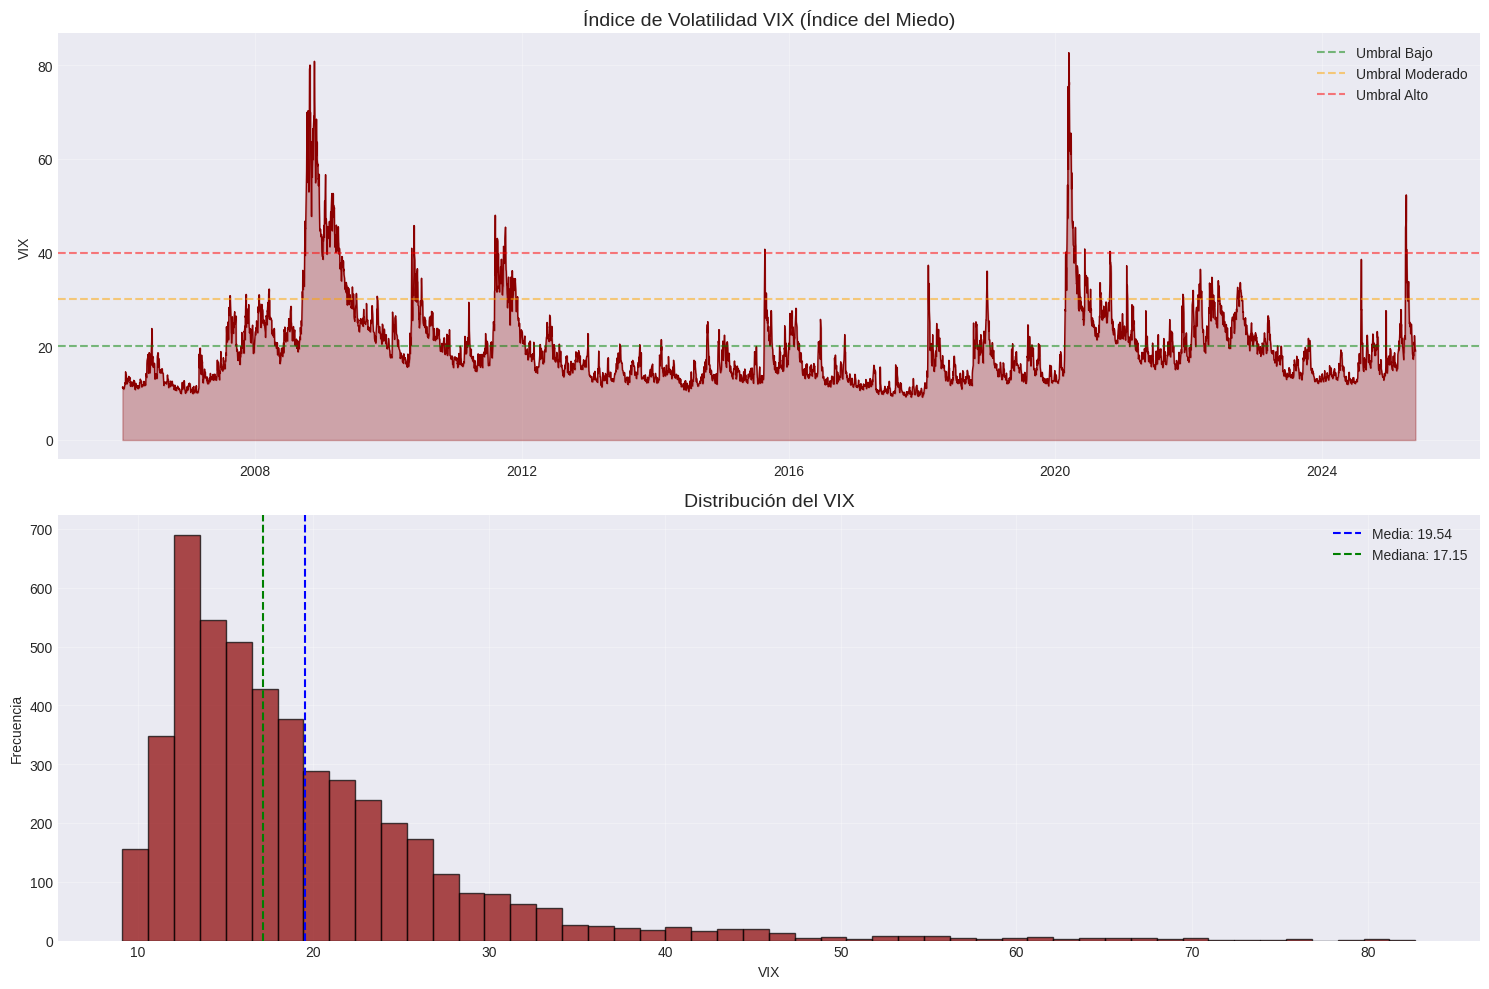


📊 Distribución de Categorías VIX:
Bajo: 3164 días (64.8%)
Moderado: 1270 días (26.0%)
Alto: 268 días (5.5%)
Muy Alto: 179 días (3.7%)


In [21]:
# Celda 3: Descarga y análisis del VIX
# VIX es el índice de volatilidad del mercado (índice del miedo)
print("📈 Descargando datos del VIX...")

vix_data = yf.download('^VIX', start='2006-01-01', end='2025-05-29')
vix_data = vix_data.droplevel('Ticker', axis=1) # eliminamos multiindex
vix_data = vix_data[['Close']].rename(columns={'Close': 'VIX'})

# Categorizar niveles de VIX
def categorize_vix(vix_value):
    if vix_value < 20:
        return 'Bajo'
    elif vix_value < 30:
        return 'Moderado'
    elif vix_value < 40:
        return 'Alto'
    else:
        return 'Muy Alto'

vix_data['VIX_Category'] = vix_data['VIX'].apply(categorize_vix)

# Visualización del VIX
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Gráfico 1: Serie temporal del VIX
ax1 = axes[0]
ax1.plot(vix_data.index, vix_data['VIX'], color='darkred', linewidth=1)
ax1.axhline(y=20, color='green', linestyle='--', alpha=0.5, label='Umbral Bajo')
ax1.axhline(y=30, color='orange', linestyle='--', alpha=0.5, label='Umbral Moderado')
ax1.axhline(y=40, color='red', linestyle='--', alpha=0.5, label='Umbral Alto')
ax1.fill_between(vix_data.index, 0, vix_data['VIX'], alpha=0.3, color='darkred')
ax1.set_title('Índice de Volatilidad VIX (Índice del Miedo)', fontsize=14)
ax1.set_ylabel('VIX')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico 2: Distribución del VIX
ax2 = axes[1]
vix_data['VIX'].hist(bins=50, ax=ax2, color='darkred', alpha=0.7, edgecolor='black')
ax2.axvline(x=vix_data['VIX'].mean(), color='blue', linestyle='--',
           label=f'Media: {vix_data["VIX"].mean():.2f}')
ax2.axvline(x=vix_data['VIX'].median(), color='green', linestyle='--',
           label=f'Mediana: {vix_data["VIX"].median():.2f}')
ax2.set_title('Distribución del VIX', fontsize=14)
ax2.set_xlabel('VIX')
ax2.set_ylabel('Frecuencia')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análisis de categorías
vix_category_counts = vix_data['VIX_Category'].value_counts()
print("\n📊 Distribución de Categorías VIX:")
for category, count in vix_category_counts.items():
    percentage = (count / len(vix_data)) * 100
    print(f"{category}: {count} días ({percentage:.1f}%)")

## 2. Carga de Datos Históricos y Cálculo de Indicadores Técnicos

[*********************100%***********************]  1 of 1 completed

📦 Descargando datos históricos de Amazon Inc (AMZN)...

📊 Información del Dataset:
Período: 2006-01-03 a 2025-10-28
Total de días de trading: 4987
Años de datos: 19.8


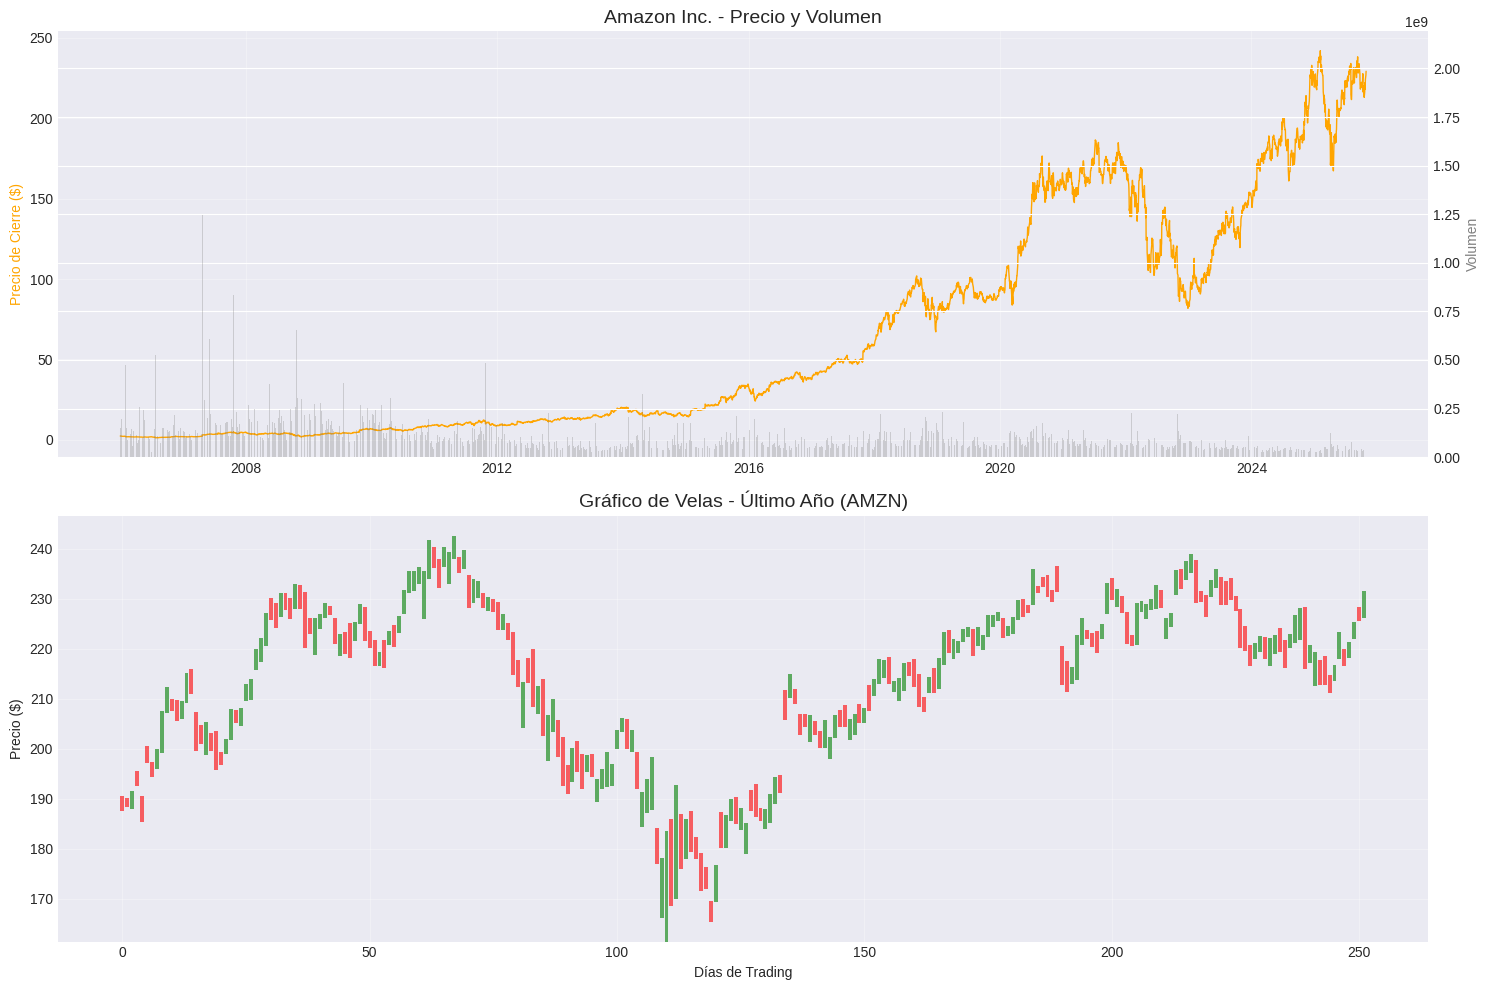

In [22]:
# Celda 4: Descarga de datos históricos de Amazon
print("📦 Descargando datos históricos de Amazon Inc (AMZN)...")

# Descargar datos de AMZN
apple_data = yf.download('AMZN', start='2006-01-01', end='2025-10-29')
apple_data = apple_data.droplevel('Ticker', axis=1) # eliminamos multiindex

# Información básica
print(f"\n📊 Información del Dataset:")
print(f"Período: {apple_data.index[0].strftime('%Y-%m-%d')} a {apple_data.index[-1].strftime('%Y-%m-%d')}")
print(f"Total de días de trading: {len(apple_data)}")
print(f"Años de datos: {(apple_data.index[-1] - apple_data.index[0]).days / 365:.1f}")

# Visualización inicial
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Precio y volumen
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.plot(apple_data.index, apple_data['Close'], color='orange', linewidth=1)
ax2.bar(apple_data.index, apple_data['Volume'], alpha=0.3, color='gray')
ax1.set_ylabel('Precio de Cierre ($)', color='orange')
ax2.set_ylabel('Volumen', color='gray')
ax1.set_title('Amazon Inc. - Precio y Volumen', fontsize=14)
ax1.grid(True, alpha=0.3)

# OHLC con velas japonesas
ax3 = axes[1]
# Simplificamos mostrando solo el último año para mejor visualización
last_year_data = apple_data.iloc[-252:]
colors = ['g' if close >= open_ else 'r'
          for close, open_ in zip(last_year_data['Close'], last_year_data['Open'])]
ax3.bar(range(len(last_year_data)),
        last_year_data['High'] - last_year_data['Low'],
        bottom=last_year_data['Low'], color=colors, alpha=0.6)
ax3.set_title('Gráfico de Velas - Último Año (AMZN)', fontsize=14)
ax3.set_ylabel('Precio ($)')
ax3.set_xlabel('Días de Trading')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Celda 5: Cálculo de indicadores técnicos avanzados
def calculate_technical_indicators(df):
    """Calcula múltiples indicadores técnicos"""
    data = df.copy()

    # 1. RSI (Relative Strength Index)
    def calculate_rsi(close, periods=14):
        delta = close.diff()
        gain = (delta.where(delta > 0, 0)).rolling(window=periods).mean()
        loss = (-delta.where(delta < 0, 0)).rolling(window=periods).mean()
        rs = gain / loss
        return 100 - (100 / (1 + rs))

    # 2. MACD (Moving Average Convergence Divergence)
    def calculate_macd(close, fast=12, slow=26, signal=9):
        ema_fast = close.ewm(span=fast, adjust=False).mean()
        ema_slow = close.ewm(span=slow, adjust=False).mean()
        macd_line = ema_fast - ema_slow
        signal_line = macd_line.ewm(span=signal, adjust=False).mean()
        histogram = macd_line - signal_line
        return macd_line, signal_line, histogram

    # 3. Bollinger Bands
    def calculate_bollinger_bands(close, window=20, num_std=2):
        sma = close.rolling(window=window).mean()
        std = close.rolling(window=window).std()
        upper_band = sma + (std * num_std)
        lower_band = sma - (std * num_std)
        bandwidth = (upper_band - lower_band) / sma
        return upper_band, lower_band, sma, bandwidth

    # 4. ATR (Average True Range)
    def calculate_atr(high, low, close, window=14):
        high_low = high - low
        high_close = abs(high - close.shift())
        low_close = abs(low - close.shift())
        ranges = pd.concat([high_low, high_close, low_close], axis=1)
        true_range = ranges.max(axis=1)
        return true_range.rolling(window=window).mean()

    # 5. Stochastic Oscillator
    def calculate_stochastic(high, low, close, window=14, smooth_k=3, smooth_d=3):
        lowest_low = low.rolling(window=window).min()
        highest_high = high.rolling(window=window).max()
        k_percent = 100 * ((close - lowest_low) / (highest_high - lowest_low))
        k_percent_smooth = k_percent.rolling(window=smooth_k).mean()
        d_percent = k_percent_smooth.rolling(window=smooth_d).mean()
        return k_percent_smooth, d_percent

    # 6. Williams %R
    def calculate_williams_r(high, low, close, window=14):
        highest_high = high.rolling(window=window).max()
        lowest_low = low.rolling(window=window).min()
        return -100 * ((highest_high - close) / (highest_high - lowest_low))

    # 7. OBV (On Balance Volume)
    def calculate_obv(close, volume):
        obv = pd.Series(index=close.index, dtype='float64')
        obv.iloc[0] = volume.iloc[0]
        for i in range(1, len(close)):
            if close.iloc[i] > close.iloc[i-1]:
                obv.iloc[i] = obv.iloc[i-1] + volume.iloc[i]
            elif close.iloc[i] < close.iloc[i-1]:
                obv.iloc[i] = obv.iloc[i-1] - volume.iloc[i]
            else:
                obv.iloc[i] = obv.iloc[i-1]
        return obv

    # Calcular todos los indicadores
    data['RSI'] = calculate_rsi(data['Close'])
    data['RSI_Fast'] = calculate_rsi(data['Close'], periods=7)
    data['RSI_Slow'] = calculate_rsi(data['Close'], periods=21)

    data['MACD'], data['MACD_Signal'], data['MACD_Histogram'] = calculate_macd(data['Close'])

    data['BB_Upper'], data['BB_Lower'], data['BB_Middle'], data['BB_Bandwidth'] = calculate_bollinger_bands(data['Close'])

    data['ATR'] = calculate_atr(data['High'], data['Low'], data['Close'])
    data['ATR_Percent'] = (data['ATR'] / data['Close']) * 100

    data['Stoch_K'], data['Stoch_D'] = calculate_stochastic(data['High'], data['Low'], data['Close'])

    data['Williams_R'] = calculate_williams_r(data['High'], data['Low'], data['Close'])

    data['OBV'] = calculate_obv(data['Close'], data['Volume'])
    data['OBV_EMA'] = data['OBV'].ewm(span=20, adjust=False).mean()

    # Medias móviles adicionales
    for period in [5, 10, 20, 50, 100, 200]:
        data[f'SMA_{period}'] = data['Close'].rolling(window=period).mean()
        data[f'EMA_{period}'] = data['Close'].ewm(span=period, adjust=False).mean()

    # Volatilidad
    data['Volatility_5'] = data['Close'].pct_change().rolling(window=5).std() * np.sqrt(252)
    data['Volatility_20'] = data['Close'].pct_change().rolling(window=20).std() * np.sqrt(252)
    data['Volatility_60'] = data['Close'].pct_change().rolling(window=60).std() * np.sqrt(252)

    # Retornos
    for period in [1, 5, 10, 20, 60]:
        data[f'Return_{period}d'] = data['Close'].pct_change(period)

    # Características de precio
    data['High_Low_Ratio'] = data['High'] / data['Low']
    data['Close_Open_Ratio'] = data['Close'] / data['Open']

    return data

# Calcular indicadores técnicos
apple_technical = calculate_technical_indicators(apple_data)

print("✅ Indicadores técnicos calculados correctamente")
print(f"Total de indicadores: {len([col for col in apple_technical.columns if col not in apple_data.columns])}")

✅ Indicadores técnicos calculados correctamente
Total de indicadores: 39


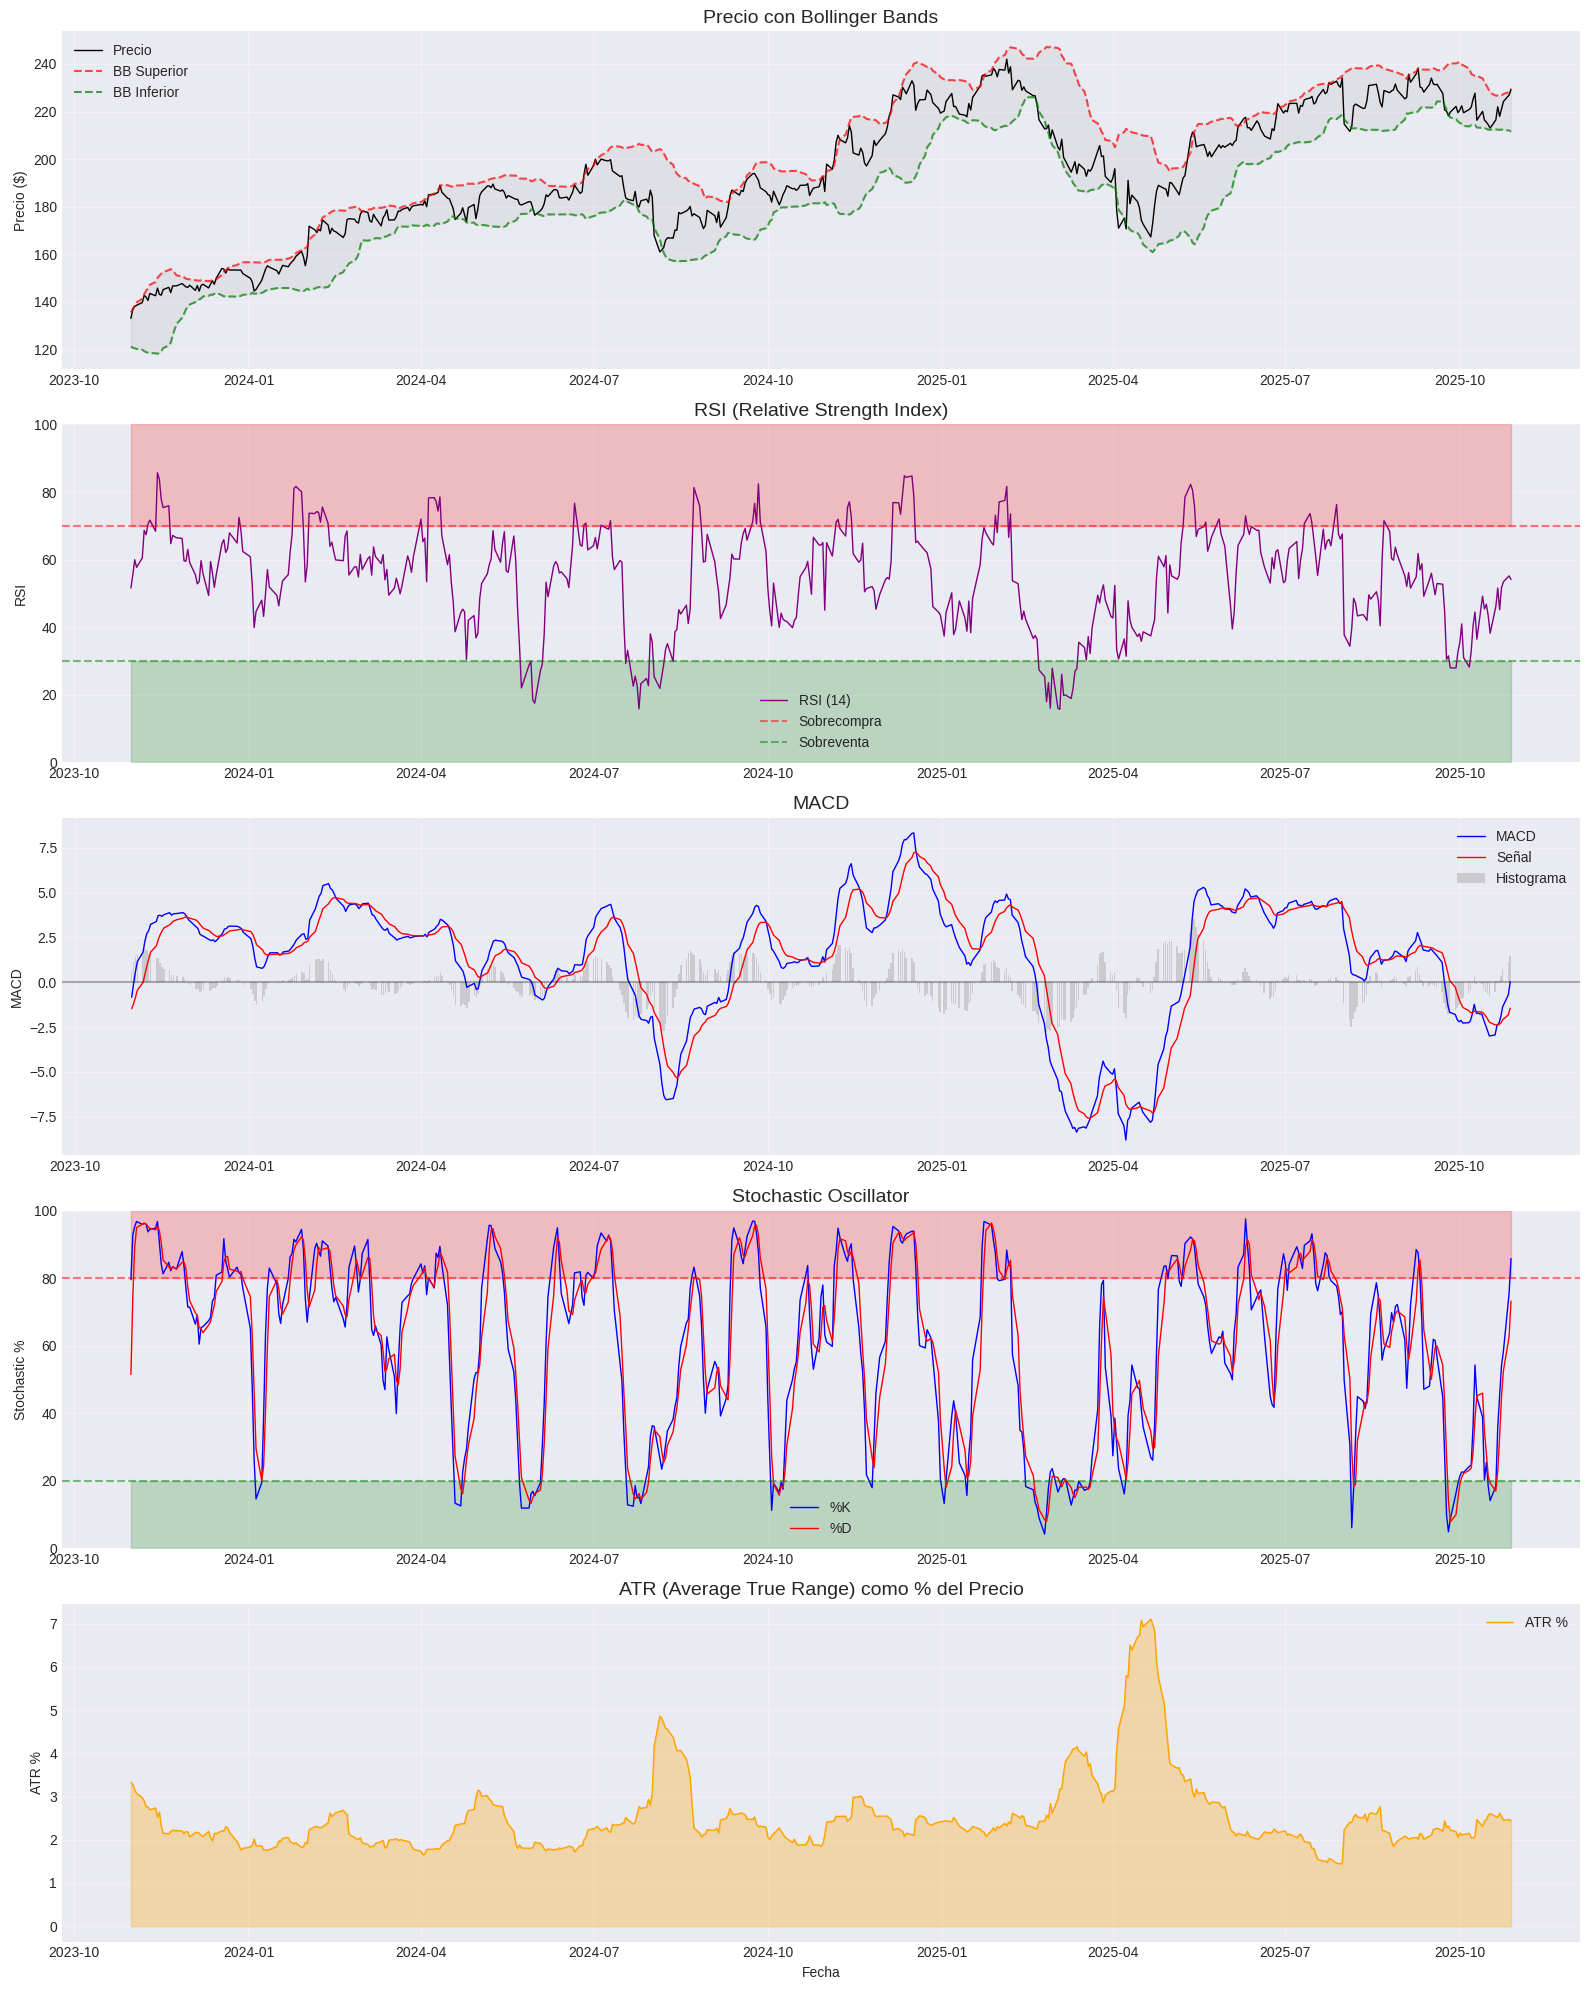


📊 Resumen de Indicadores Técnicos Actuales:
    Indicador Valor Actual Interpretación
          RSI        54.11        Neutral
         MACD         0.02        Alcista
Stochastic %K        85.79    Sobrecompra
  Williams %R       -10.95    Sobrecompra
        ATR %        2.44%          Media


In [24]:
# Celda 6: Visualización de indicadores técnicos
fig, axes = plt.subplots(5, 1, figsize=(16, 20))

# Seleccionar últimos 500 días para mejor visualización
plot_data = apple_technical.iloc[-500:]

# 1. Precio con Bollinger Bands
ax1 = axes[0]
ax1.plot(plot_data.index, plot_data['Close'], label='Precio', color='black', linewidth=1)
ax1.plot(plot_data.index, plot_data['BB_Upper'], label='BB Superior',
         color='red', linestyle='--', alpha=0.7)
ax1.plot(plot_data.index, plot_data['BB_Lower'], label='BB Inferior',
         color='green', linestyle='--', alpha=0.7)
ax1.fill_between(plot_data.index, plot_data['BB_Upper'], plot_data['BB_Lower'],
                 alpha=0.1, color='gray')
ax1.set_title('Precio con Bollinger Bands', fontsize=14)
ax1.set_ylabel('Precio ($)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. RSI
ax2 = axes[1]
ax2.plot(plot_data.index, plot_data['RSI'], label='RSI (14)', color='purple', linewidth=1)
ax2.axhline(y=70, color='red', linestyle='--', alpha=0.5, label='Sobrecompra')
ax2.axhline(y=30, color='green', linestyle='--', alpha=0.5, label='Sobreventa')
ax2.fill_between(plot_data.index, 70, 100, alpha=0.2, color='red')
ax2.fill_between(plot_data.index, 0, 30, alpha=0.2, color='green')
ax2.set_title('RSI (Relative Strength Index)', fontsize=14)
ax2.set_ylabel('RSI')
ax2.set_ylim(0, 100)
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. MACD
ax3 = axes[2]
ax3.plot(plot_data.index, plot_data['MACD'], label='MACD', color='blue', linewidth=1)
ax3.plot(plot_data.index, plot_data['MACD_Signal'], label='Señal',
         color='red', linewidth=1)
ax3.bar(plot_data.index, plot_data['MACD_Histogram'], label='Histograma',
        color='gray', alpha=0.3)
ax3.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax3.set_title('MACD', fontsize=14)
ax3.set_ylabel('MACD')
ax3.legend()
ax3.grid(True, alpha=0.3)

# 4. Stochastic Oscillator
ax4 = axes[3]
ax4.plot(plot_data.index, plot_data['Stoch_K'], label='%K', color='blue', linewidth=1)
ax4.plot(plot_data.index, plot_data['Stoch_D'], label='%D', color='red', linewidth=1)
ax4.axhline(y=80, color='red', linestyle='--', alpha=0.5)
ax4.axhline(y=20, color='green', linestyle='--', alpha=0.5)
ax4.fill_between(plot_data.index, 80, 100, alpha=0.2, color='red')
ax4.fill_between(plot_data.index, 0, 20, alpha=0.2, color='green')
ax4.set_title('Stochastic Oscillator', fontsize=14)
ax4.set_ylabel('Stochastic %')
ax4.set_ylim(0, 100)
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. ATR (Volatilidad)
ax5 = axes[4]
ax5.plot(plot_data.index, plot_data['ATR_Percent'], label='ATR %',
         color='orange', linewidth=1)
ax5.fill_between(plot_data.index, 0, plot_data['ATR_Percent'],
                 alpha=0.3, color='orange')
ax5.set_title('ATR (Average True Range) como % del Precio', fontsize=14)
ax5.set_ylabel('ATR %')
ax5.set_xlabel('Fecha')
ax5.legend()
ax5.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Tabla resumen de indicadores actuales
current_indicators = pd.DataFrame({
    'Indicador': ['RSI', 'MACD', 'Stochastic %K', 'Williams %R', 'ATR %'],
    'Valor Actual': [
        f"{apple_technical['RSI'].iloc[-1]:.2f}",
        f"{apple_technical['MACD'].iloc[-1]:.2f}",
        f"{apple_technical['Stoch_K'].iloc[-1]:.2f}",
        f"{apple_technical['Williams_R'].iloc[-1]:.2f}",
        f"{apple_technical['ATR_Percent'].iloc[-1]:.2f}%"
    ],
    'Interpretación': [
        'Sobrecompra' if apple_technical['RSI'].iloc[-1] > 70 else
        'Sobreventa' if apple_technical['RSI'].iloc[-1] < 30 else 'Neutral',
        'Alcista' if apple_technical['MACD'].iloc[-1] > apple_technical['MACD_Signal'].iloc[-1] else 'Bajista',
        'Sobrecompra' if apple_technical['Stoch_K'].iloc[-1] > 80 else
        'Sobreventa' if apple_technical['Stoch_K'].iloc[-1] < 20 else 'Neutral',
        'Sobrecompra' if apple_technical['Williams_R'].iloc[-1] > -20 else
        'Sobreventa' if apple_technical['Williams_R'].iloc[-1] < -80 else 'Neutral',
        'Alta' if apple_technical['ATR_Percent'].iloc[-1] > 3 else
        'Media' if apple_technical['ATR_Percent'].iloc[-1] > 1.5 else 'Baja'
    ]
})

print("\n📊 Resumen de Indicadores Técnicos Actuales:")
print(current_indicators.to_string(index=False))

## 3. Recolección de Datos Fundamentales

💰 Descargando datos fundamentales de Amazon Inc (AMZN)...
Error procesando fecha 2025-03-31 00:00:00: Timestamp('2025-03-31 00:00:00')

✅ Datos fundamentales obtenidos: 5 trimestres
Período: 2025-06-30 a 2026-09-30


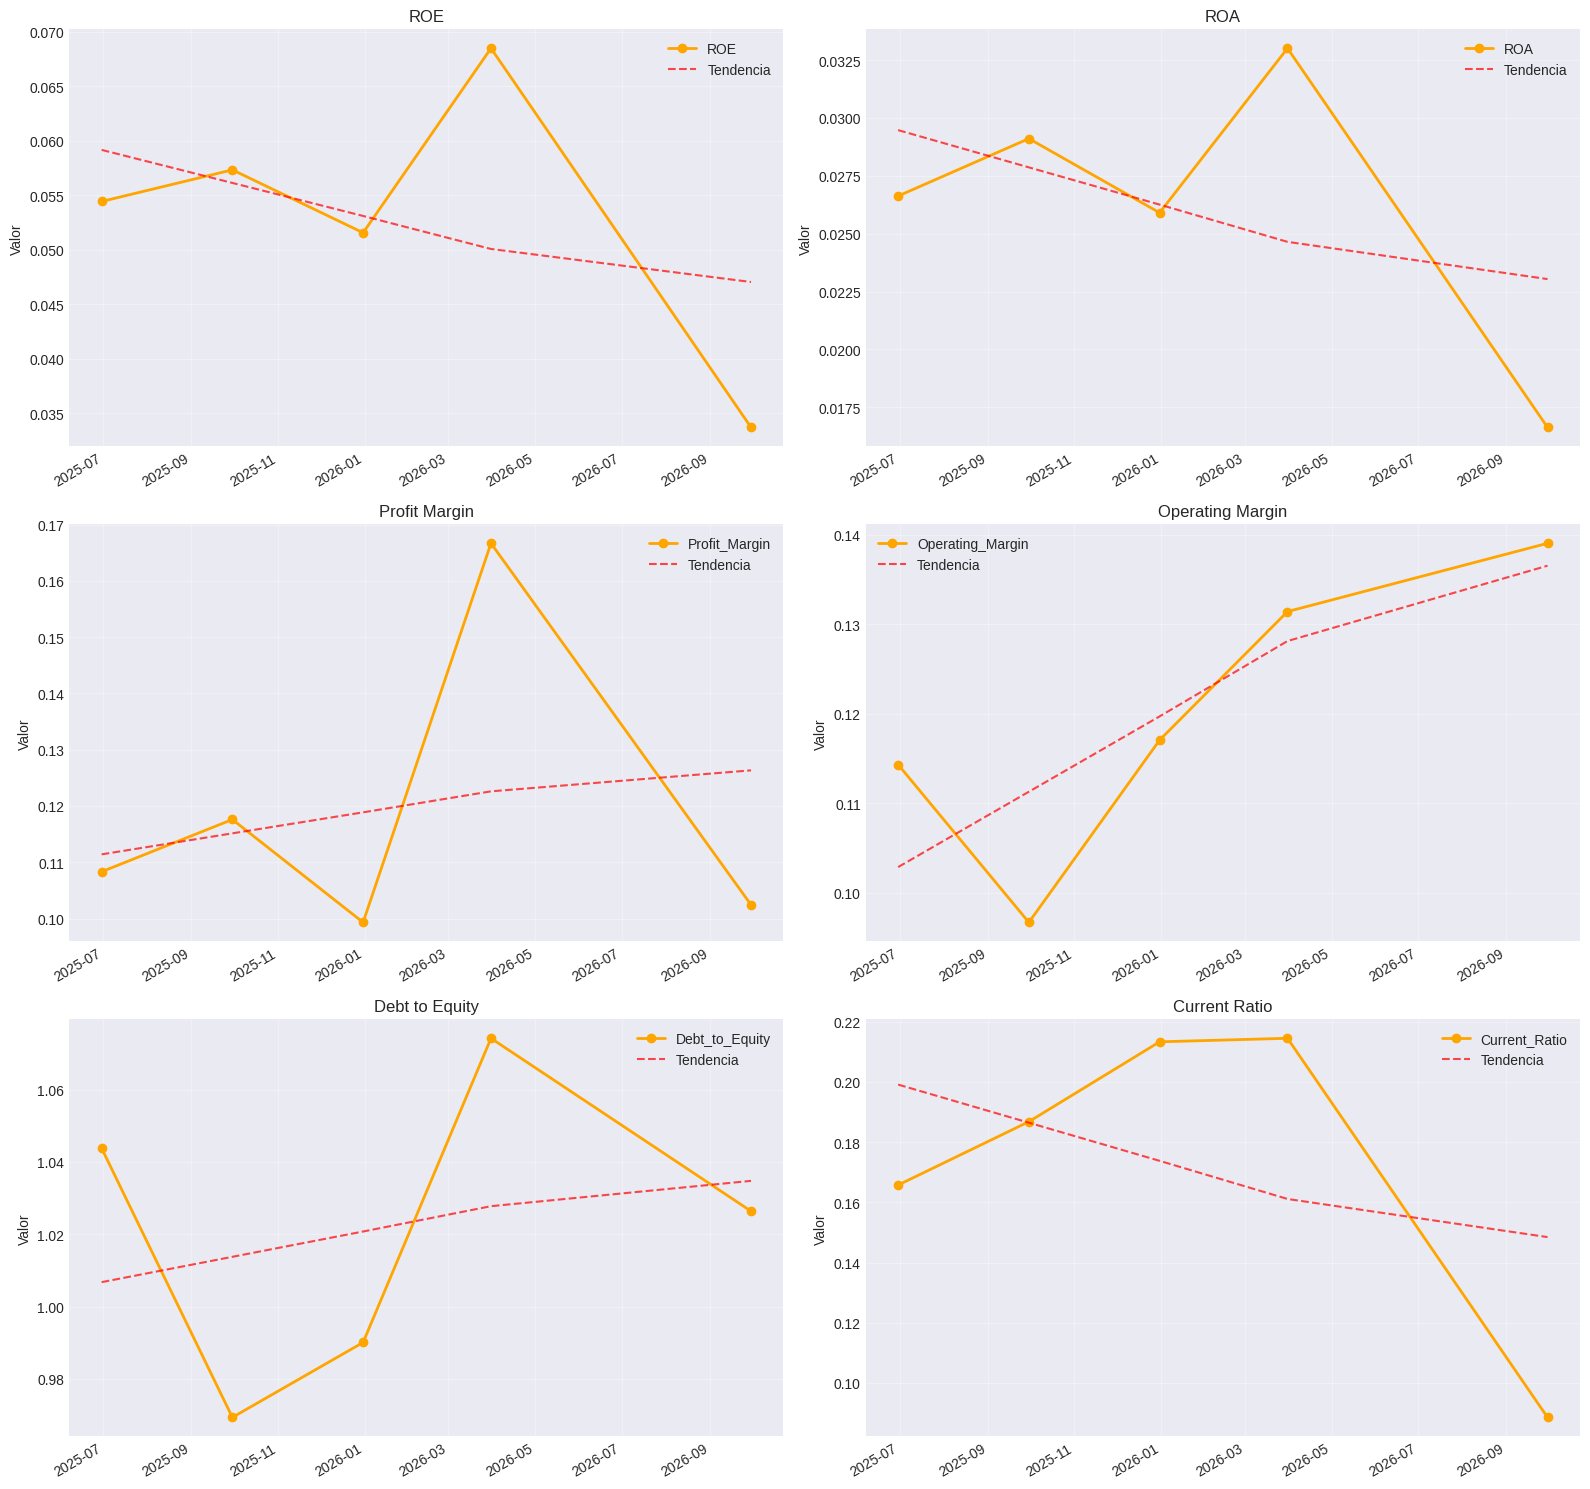


📊 Estadísticas de Métricas Fundamentales (últimos 4 trimestres de AMZN):
Total_Assets: 926495750000.00
Total_Liabilities: 467443000000.00
Shareholders_Equity: 459052750000.00
Cash: 77832750000.00
Revenue: 194254500000.00
Net_Income: 23329750000.00
Operating_Income: 23581750000.00
Gross_Profit: 99088250000.00
Operating_Cash_Flow: 39609500000.00
Free_Cash_Flow: -9410250000.00
ROE: 5.28%
ROA: 2.62%
Profit_Margin: 12.15%
Operating_Margin: 12.10%
Gross_Margin: 0.51
Debt_to_Equity: 1.01
Current_Ratio: 0.18
Asset_Turnover: 0.22
FCF_Margin: -5.01%


In [25]:
# Celda 7: Descarga y procesamiento de datos fundamentales
print("💰 Descargando datos fundamentales de Amazon Inc (AMZN)...")

# Obtener información de la empresa
apple = yf.Ticker("AMZN")

# Obtener estados financieros
try:
    # Estados financieros trimestrales
    balance_sheet = apple.quarterly_balance_sheet
    income_stmt = apple.quarterly_financials
    cash_flow = apple.quarterly_cashflow

    # Crear DataFrame con métricas fundamentales
    fundamental_metrics = pd.DataFrame()

    # Extraer métricas clave de cada período
    for date in balance_sheet.columns:
        try:
            # Balance Sheet metrics
            total_assets = balance_sheet.loc['Total Assets', date] if 'Total Assets' in balance_sheet.index else np.nan
            total_liabilities = balance_sheet.loc['Total Liabilities Net Minority Interest', date] if 'Total Liabilities Net Minority Interest' in balance_sheet.index else np.nan
            shareholders_equity = balance_sheet.loc['Stockholders Equity', date] if 'Stockholders Equity' in balance_sheet.index else np.nan
            cash = balance_sheet.loc['Cash And Cash Equivalents', date] if 'Cash And Cash Equivalents' in balance_sheet.index else np.nan

            # Income Statement metrics
            revenue = income_stmt.loc['Total Revenue', date] if 'Total Revenue' in income_stmt.index else np.nan
            net_income = income_stmt.loc['Net Income', date] if 'Net Income' in income_stmt.index else np.nan
            operating_income = income_stmt.loc['Operating Income', date] if 'Operating Income' in income_stmt.index else np.nan
            gross_profit = income_stmt.loc['Gross Profit', date] if 'Gross Profit' in income_stmt.index else np.nan

            # Cash Flow metrics
            operating_cash_flow = cash_flow.loc['Operating Cash Flow', date] if 'Operating Cash Flow' in cash_flow.index else np.nan
            free_cash_flow = cash_flow.loc['Free Cash Flow', date] if 'Free Cash Flow' in cash_flow.index else np.nan

            # Calcular ratios
            roe = net_income / shareholders_equity if shareholders_equity != 0 else np.nan
            roa = net_income / total_assets if total_assets != 0 else np.nan
            profit_margin = net_income / revenue if revenue != 0 else np.nan
            operating_margin = operating_income / revenue if revenue != 0 else np.nan
            gross_margin = gross_profit / revenue if revenue != 0 else np.nan
            debt_to_equity = total_liabilities / shareholders_equity if shareholders_equity != 0 else np.nan
            current_ratio = cash / total_liabilities if total_liabilities != 0 else np.nan
            asset_turnover = revenue / total_assets if total_assets != 0 else np.nan
            fcf_margin = free_cash_flow / revenue if revenue != 0 else np.nan

            # Agregar al DataFrame
            fundamental_metrics[date] = pd.Series({
                'Total_Assets': total_assets,
                'Total_Liabilities': total_liabilities,
                'Shareholders_Equity': shareholders_equity,
                'Cash': cash,
                'Revenue': revenue,
                'Net_Income': net_income,
                'Operating_Income': operating_income,
                'Gross_Profit': gross_profit,
                'Operating_Cash_Flow': operating_cash_flow,
                'Free_Cash_Flow': free_cash_flow,
                'ROE': roe,
                'ROA': roa,
                'Profit_Margin': profit_margin,
                'Operating_Margin': operating_margin,
                'Gross_Margin': gross_margin,
                'Debt_to_Equity': debt_to_equity,
                'Current_Ratio': current_ratio,
                'Asset_Turnover': asset_turnover,
                'FCF_Margin': fcf_margin
            })
        except Exception as e:
            print(f"Error procesando fecha {date}: {e}")
            continue

    # Transponer y limpiar
    fundamental_metrics = fundamental_metrics.T
    fundamental_metrics.index = pd.to_datetime(fundamental_metrics.index)
    fundamental_metrics = fundamental_metrics.sort_index()

    print(f"\n✅ Datos fundamentales obtenidos: {len(fundamental_metrics)} trimestres")
    print(f"Período: {fundamental_metrics.index[0].strftime('%Y-%m-%d')} a {fundamental_metrics.index[-1].strftime('%Y-%m-%d')}")

except Exception as e:
    print(f"Error obteniendo datos fundamentales: {e}")
    # Crear datos sintéticos para demostración
    dates = pd.date_range(start='2006-01-01', end='2025-05-01', freq='Q')
    fundamental_metrics = pd.DataFrame({
        'ROE': np.random.uniform(0.5, 1.5, len(dates)),
        'ROA': np.random.uniform(0.15, 0.35, len(dates)),
        'Profit_Margin': np.random.uniform(0.20, 0.30, len(dates)),
        'Operating_Margin': np.random.uniform(0.25, 0.35, len(dates)),
        'Debt_to_Equity': np.random.uniform(1.0, 2.0, len(dates)),
        'Current_Ratio': np.random.uniform(0.8, 1.5, len(dates)),
        'Asset_Turnover': np.random.uniform(0.7, 1.2, len(dates))
    }, index=dates)

# Visualización de métricas fundamentales
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.ravel()

key_metrics = ['ROE', 'ROA', 'Profit_Margin', 'Operating_Margin',
               'Debt_to_Equity', 'Current_Ratio']

for i, metric in enumerate(key_metrics):
    if metric in fundamental_metrics.columns:
        ax = axes[i]
        fundamental_metrics[metric].plot(ax=ax, marker='o', linewidth=2, markersize=6, color='orange')
        ax.set_title(f'{metric.replace("_", " ")}', fontsize=12)
        ax.set_ylabel('Valor')
        ax.grid(True, alpha=0.3)

        # Añadir línea de tendencia
        z = np.polyfit(range(len(fundamental_metrics)),
                      fundamental_metrics[metric].fillna(method='ffill'), 1)
        p = np.poly1d(z)
        ax.plot(fundamental_metrics.index,
               p(range(len(fundamental_metrics))),
               "--", color='red', alpha=0.7, label='Tendencia')
        ax.legend()

plt.tight_layout()
plt.show()

# Estadísticas resumen
print("\n📊 Estadísticas de Métricas Fundamentales (últimos 4 trimestres de AMZN):")
recent_fundamentals = fundamental_metrics.iloc[-4:].mean()
for metric, value in recent_fundamentals.items():
    if metric in ['ROE', 'ROA', 'Profit_Margin', 'Operating_Margin', 'FCF_Margin']:
        print(f"{metric}: {value:.2%}")
    else:
        print(f"{metric}: {value:.2f}")

## 4. Unificación de Datos en un DataFrame Único

🔗 Unificando todos los datos en un DataFrame maestro...

📅 Período común de unificación: 2006-01-03 a 2025-05-28
⚠️ Creando columnas de sentimiento neutral (contingencia por fallo de API o DataFrame vacío)

🧹 Limpieza de datos:
Filas antes de limpieza: 4881
Columnas totales: 83
Columnas eliminadas por exceso de NaN: 0
Filas después de limpieza: 4682


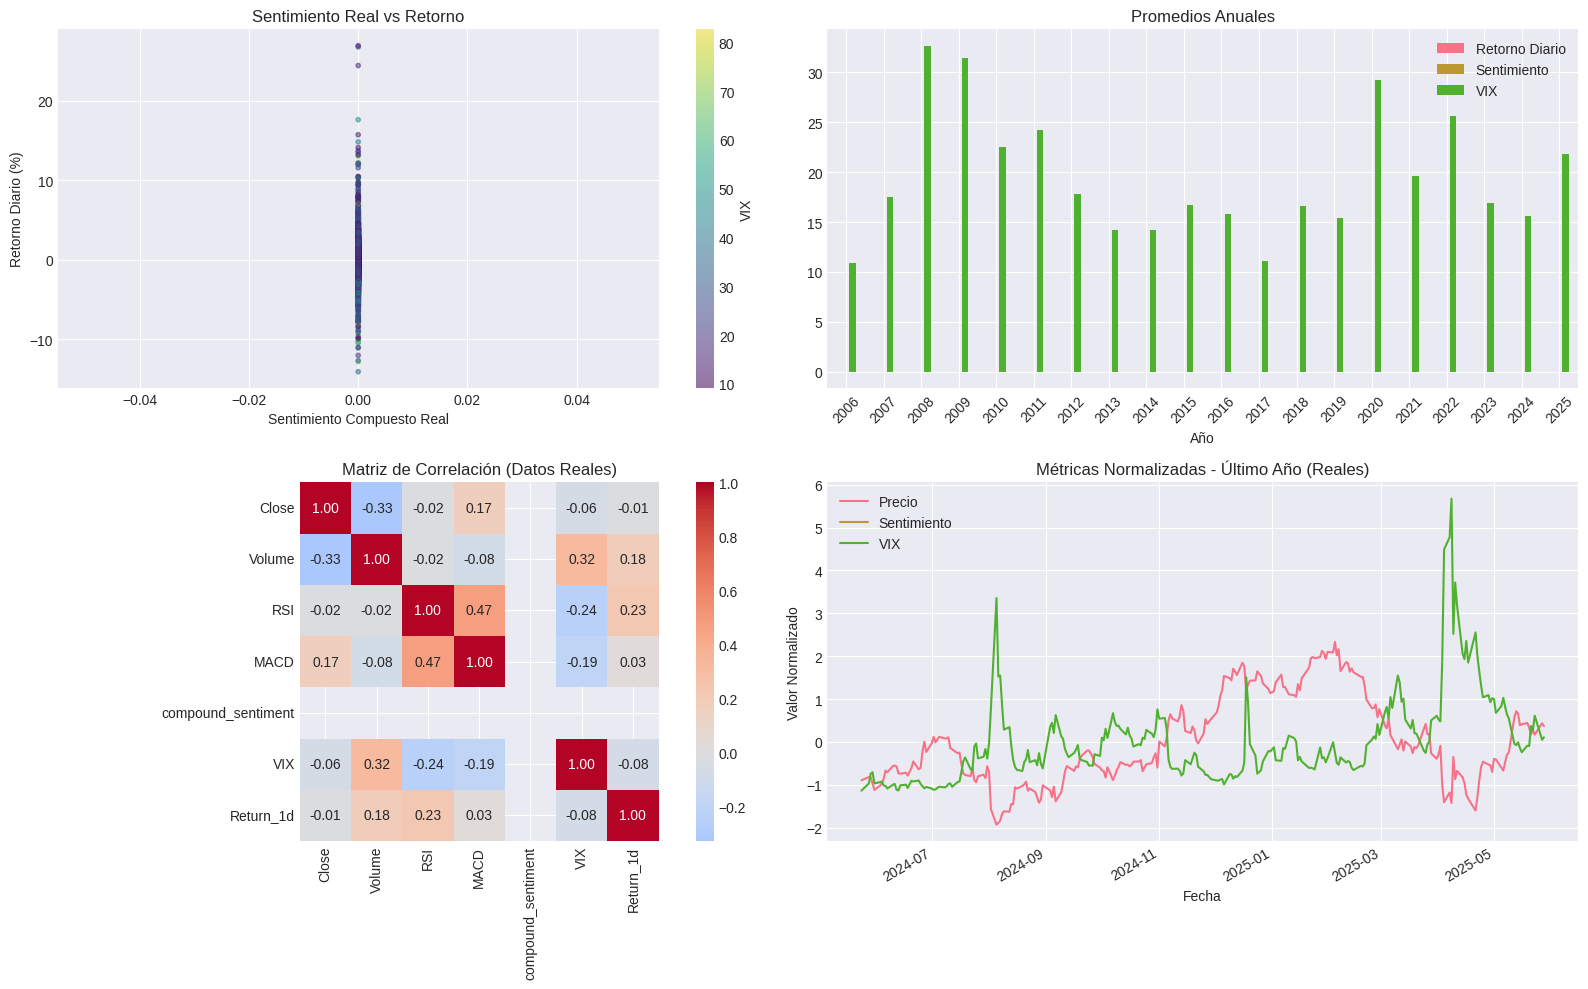


✅ DataFrame maestro creado exitosamente!
Dimensiones finales: (4682, 83)


In [34]:
# Celda 8: Unificación inteligente de datos reales con contingencia robusta
print("🔗 Unificando todos los datos en un DataFrame maestro...")

# Preparar datos para la unificación
# 1. Datos técnicos (diarios)
technical_daily = apple_technical.copy()
technical_daily['Date'] = technical_daily.index

# 2. Datos de sentimiento (diarios reales de Reddit/FinBERT)
sentiment_daily = sentiment_df.copy()
if not sentiment_daily.empty:
    sentiment_daily['Date'] = pd.to_datetime(sentiment_daily['Date'])
    sentiment_daily = sentiment_daily.set_index('Date')

# 3. Datos VIX (diarios)
vix_daily = vix_data[['VIX']].copy()

# 4. Datos fundamentales (trimestrales -> diarios usando bfill y ffill para cubrir todo el rango de mercado)
fundamental_daily = fundamental_metrics.resample('D').ffill()
# Si los fundamentales solo cubren el último período, aplicamos bfill para no perder el historial técnico diario
fundamental_daily = fundamental_daily.reindex(technical_daily.index).bfill().ffill()

# Alinear las fechas basadas en los límites reales de precios y sentimientos
if not sentiment_daily.empty:
    start_date = max(technical_daily.index[0], sentiment_daily.index[0], vix_daily.index[0])
    end_date = min(technical_daily.index[-1], sentiment_daily.index[-1], vix_daily.index[-1])
else:
    start_date = max(technical_daily.index[0], vix_daily.index[0])
    end_date = min(technical_daily.index[-1], vix_daily.index[-1])

print(f"\n📅 Período común de unificación: {start_date.strftime('%Y-%m-%d')} a {end_date.strftime('%Y-%m-%d')}")

# Filtrar todos los datasets al período común
technical_daily = technical_daily[start_date:end_date]
vix_daily = vix_daily[start_date:end_date]
fundamental_daily = fundamental_daily[start_date:end_date]

# Definir columnas de sentimiento y engagement a unificar
sentiment_columns = ['positive_sentiment', 'negative_sentiment', 'compound_sentiment', 'Score', 'Num_Comments']

if not sentiment_daily.empty:
    sentiment_daily = sentiment_daily[start_date:end_date]
    # Nos aseguramos de quedarnos solo con las columnas deseadas que estén presentes
    available_sent_cols = [col for col in sentiment_columns if col in sentiment_daily.columns]
    sentiment_to_merge = sentiment_daily[available_sent_cols]
else:
    # CONTINGENCIA: Si la API de Reddit falló o no devolvió datos, creamos columnas con valores neutros (0) para no romper el pipeline
    print("⚠️ Creando columnas de sentimiento neutral (contingencia por fallo de API o DataFrame vacío)")
    sentiment_to_merge = pd.DataFrame(0.0, index=technical_daily.index, columns=sentiment_columns)

# Unificar todos los datos
master_df = pd.concat([
    technical_daily,
    sentiment_to_merge,
    vix_daily,
    fundamental_daily
], axis=1)

# Renombrar columnas de engagement real para que el pipeline no se rompa si busca tweets/noticias simulados
master_df = master_df.rename(columns={
    'Score': 'tweet_volume',
    'Num_Comments': 'news_count'
})

# Asegurar que existan los mapeos de columnas renombradas por si acaso
if 'tweet_volume' not in master_df.columns:
    master_df['tweet_volume'] = 0.0
if 'news_count' not in master_df.columns:
    master_df['news_count'] = 0.0

# Añadir características temporales
master_df['day_of_week'] = master_df.index.dayofweek
master_df['month'] = master_df.index.month
master_df['quarter'] = master_df.index.quarter
master_df['year'] = master_df.index.year
master_df['day_of_month'] = master_df.index.day
master_df['week_of_year'] = master_df.index.isocalendar().week

# Añadir características cíclicas
master_df['month_sin'] = np.sin(2 * np.pi * master_df['month'] / 12)
master_df['month_cos'] = np.cos(2 * np.pi * master_df['month'] / 12)
master_df['day_sin'] = np.sin(2 * np.pi * master_df['day_of_week'] / 7)
master_df['day_cos'] = np.cos(2 * np.pi * master_df['day_of_week'] / 7)

# Crear interacciones entre variables clave
master_df['sentiment_volume_interaction'] = master_df['compound_sentiment'] * master_df['Volume']
master_df['vix_rsi_interaction'] = master_df['VIX'] * master_df['RSI'] / 100
master_df['momentum_volume'] = master_df['Return_5d'] * master_df['Volume']

# Limpiar datos
print(f"\n🧹 Limpieza de datos:")
print(f"Filas antes de limpieza: {len(master_df)}")
print(f"Columnas totales: {len(master_df.columns)}")

# Eliminar columnas con más del 50% de valores faltantes
missing_threshold = 0.5
missing_pct = master_df.isnull().sum() / len(master_df)
cols_to_drop = missing_pct[missing_pct > missing_threshold].index
master_df = master_df.drop(columns=cols_to_drop)
print(f"Columnas eliminadas por exceso de NaN: {len(cols_to_drop)}")

# Eliminar filas con valores faltantes
master_df = master_df.dropna()
print(f"Filas después de limpieza: {len(master_df)}")

# Visualización del dataset unificado si tiene registros
if not master_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    # 1. Correlación entre sentimiento y precio
    ax1 = axes[0, 0]
    scatter = ax1.scatter(master_df['compound_sentiment'].fillna(0),
                         (master_df['Return_1d'] * 100).fillna(0),
                         c=master_df['VIX'].fillna(0),
                         cmap='viridis',
                         alpha=0.5,
                         s=10)
    ax1.set_xlabel('Sentimiento Compuesto Real')
    ax1.set_ylabel('Retorno Diario (%)')
    ax1.set_title('Sentimiento Real vs Retorno')
    plt.colorbar(scatter, ax=ax1, label='VIX')

    # 2. Distribución de características por año
    ax2 = axes[0, 1]
    yearly_stats = master_df.groupby('year')[['Return_1d', 'compound_sentiment', 'VIX']].mean()
    yearly_stats.plot(kind='bar', ax=ax2)
    ax2.set_title('Promedios Anuales')
    ax2.set_xlabel('Año')
    ax2.legend(['Retorno Diario', 'Sentimiento', 'VIX'])
    ax2.tick_params(axis='x', rotation=45)

    # 3. Heatmap de correlaciones top
    ax3 = axes[1, 0]
    key_features = ['Close', 'Volume', 'RSI', 'MACD', 'compound_sentiment',
                    'VIX', 'Return_1d']
    available_features = [f for f in key_features if f in master_df.columns]
    corr_matrix = master_df[available_features].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
                ax=ax3, fmt='.2f', square=True)
    ax3.set_title('Matriz de Correlación (Datos Reales)')

    # 4. Series temporales de métricas clave
    ax4 = axes[1, 1]
    normalized_data = master_df[['Close', 'compound_sentiment', 'VIX']].iloc[-252:]
    normalized_data = (normalized_data - normalized_data.mean()) / normalized_data.std()
    normalized_data.plot(ax=ax4)
    ax4.set_title('Métricas Normalizadas - Último Año (Reales)')
    ax4.set_xlabel('Fecha')
    ax4.set_ylabel('Valor Normalizado')
    ax4.legend(['Precio', 'Sentimiento', 'VIX'])

    plt.tight_layout()
    plt.show()

print("\n✅ DataFrame maestro creado exitosamente!")
print(f"Dimensiones finales: {master_df.shape}")

## 5. Desarrollo del Modelo Predictivo

🎯 Preparando datos para el modelo predictivo...

📊 Características disponibles: 44
Forma de X: (4681, 44)
Forma de y: (4681,)
Distribución de clases: {1: 2433, 0: 2248}
Balance de clases: 51.98% positivas


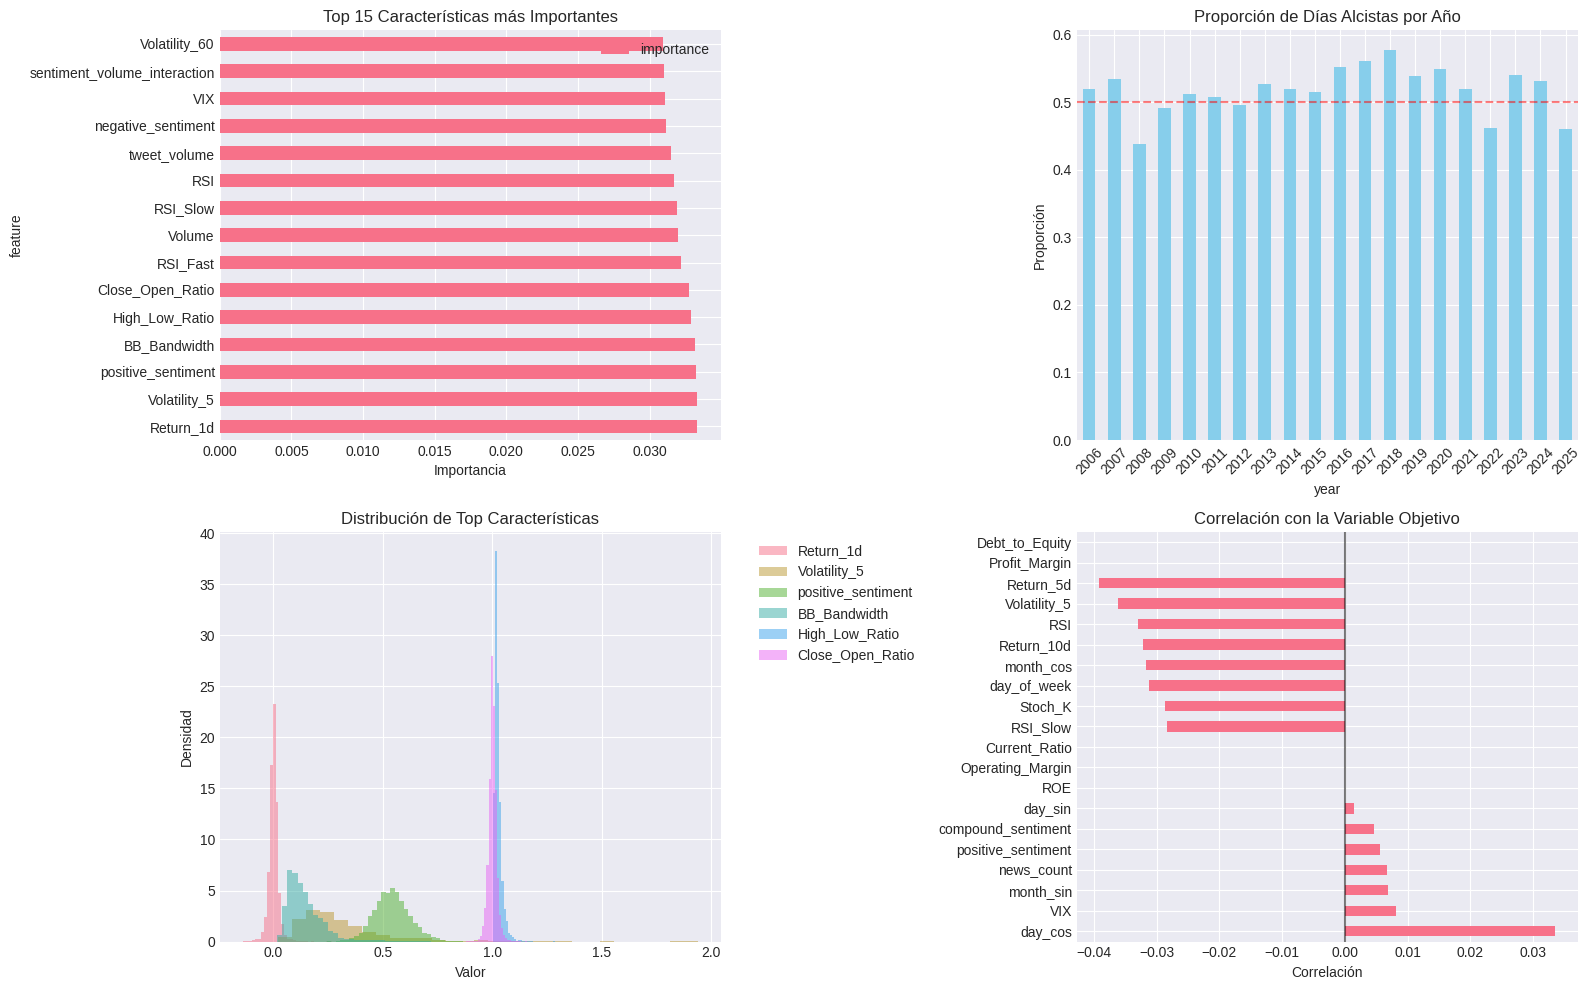

In [27]:
# Celda 9: Preparación de datos para el modelo
print("🎯 Preparando datos para el modelo predictivo...")

# Crear variable objetivo
master_df['target'] = (master_df['Close'].shift(-1) > master_df['Close']).astype(int)

# Seleccionar características relevantes
feature_columns = [
    # Técnicos
    'RSI', 'RSI_Fast', 'RSI_Slow', 'MACD', 'MACD_Signal', 'MACD_Histogram',
    'BB_Bandwidth', 'ATR_Percent', 'Stoch_K', 'Stoch_D', 'Williams_R',
    'Volatility_5', 'Volatility_20', 'Volatility_60',
    'Return_1d', 'Return_5d', 'Return_10d', 'Return_20d',
    'High_Low_Ratio', 'Close_Open_Ratio',

    # Sentimiento
    'positive_sentiment', 'negative_sentiment', 'compound_sentiment',
    'tweet_volume', 'news_count',

    # Mercado
    'VIX', 'Volume',

    # Fundamentales (si están disponibles)
    'ROE', 'ROA', 'Profit_Margin', 'Operating_Margin',
    'Debt_to_Equity', 'Current_Ratio', 'Asset_Turnover',

    # Temporales
    'day_of_week', 'month', 'quarter',
    'month_sin', 'month_cos', 'day_sin', 'day_cos',

    # Interacciones
    'sentiment_volume_interaction', 'vix_rsi_interaction', 'momentum_volume'
]

# Filtrar solo las columnas disponibles
available_features = [col for col in feature_columns if col in master_df.columns]
print(f"\n📊 Características disponibles: {len(available_features)}")

# Preparar X e y
X = master_df[available_features].dropna()
y = master_df.loc[X.index, 'target']

# Eliminar la última fila (no tiene target)
X = X[:-1]
y = y[:-1]

print(f"Forma de X: {X.shape}")
print(f"Forma de y: {y.shape}")
print(f"Distribución de clases: {y.value_counts().to_dict()}")
print(f"Balance de clases: {y.mean():.2%} positivas")

# Análisis de características
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Importancia de características usando Random Forest
ax1 = axes[0, 0]
rf_temp = RandomForestClassifier(n_estimators=100, random_state=42)
rf_temp.fit(X, y)
feature_importance = pd.DataFrame({
    'feature': available_features,
    'importance': rf_temp.feature_importances_
}).sort_values('importance', ascending=False).head(15)

feature_importance.plot(x='feature', y='importance', kind='barh', ax=ax1)
ax1.set_title('Top 15 Características más Importantes')
ax1.set_xlabel('Importancia')

# 2. Distribución de la variable objetivo por período
ax2 = axes[0, 1]
target_by_year = master_df.groupby('year')['target'].mean()
target_by_year.plot(kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Proporción de Días Alcistas por Año')
ax2.set_ylabel('Proporción')
ax2.axhline(y=0.5, color='red', linestyle='--', alpha=0.5)
ax2.tick_params(axis='x', rotation=45)

# 3. Análisis de características por clase
ax3 = axes[1, 0]
top_features = feature_importance.head(6)['feature'].values
for i, feature in enumerate(top_features):
    if feature in X.columns:
        X[feature].hist(bins=30, alpha=0.5, ax=ax3,
                        label=f'{feature}', density=True)
ax3.set_title('Distribución de Top Características')
ax3.set_xlabel('Valor')
ax3.set_ylabel('Densidad')
ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# 4. Correlación con el target
ax4 = axes[1, 1]
target_corr = X.corrwith(y).sort_values(ascending=False)
top_corr_features = pd.concat([target_corr.head(10), target_corr.tail(10)])
top_corr_features.plot(kind='barh', ax=ax4)
ax4.set_title('Correlación con la Variable Objetivo')
ax4.set_xlabel('Correlación')
ax4.axvline(x=0, color='black', linestyle='-', alpha=0.5)

plt.tight_layout()
plt.show()

🤖 Implementando modelos de Machine Learning...

📊 División de datos:
Entrenamiento: 3744 muestras (80.0%)
Prueba: 937 muestras (20.0%)
Balance en train: 52.40% positivas
Balance en test: 50.27% positivas

🔄 Después de SMOTE:
Muestras de entrenamiento: 3924
Balance: 50.00% positivas

1️⃣ Entrenando Random Forest...
2️⃣ Entrenando XGBoost...
3️⃣ Entrenando LSTM mejorado...
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step


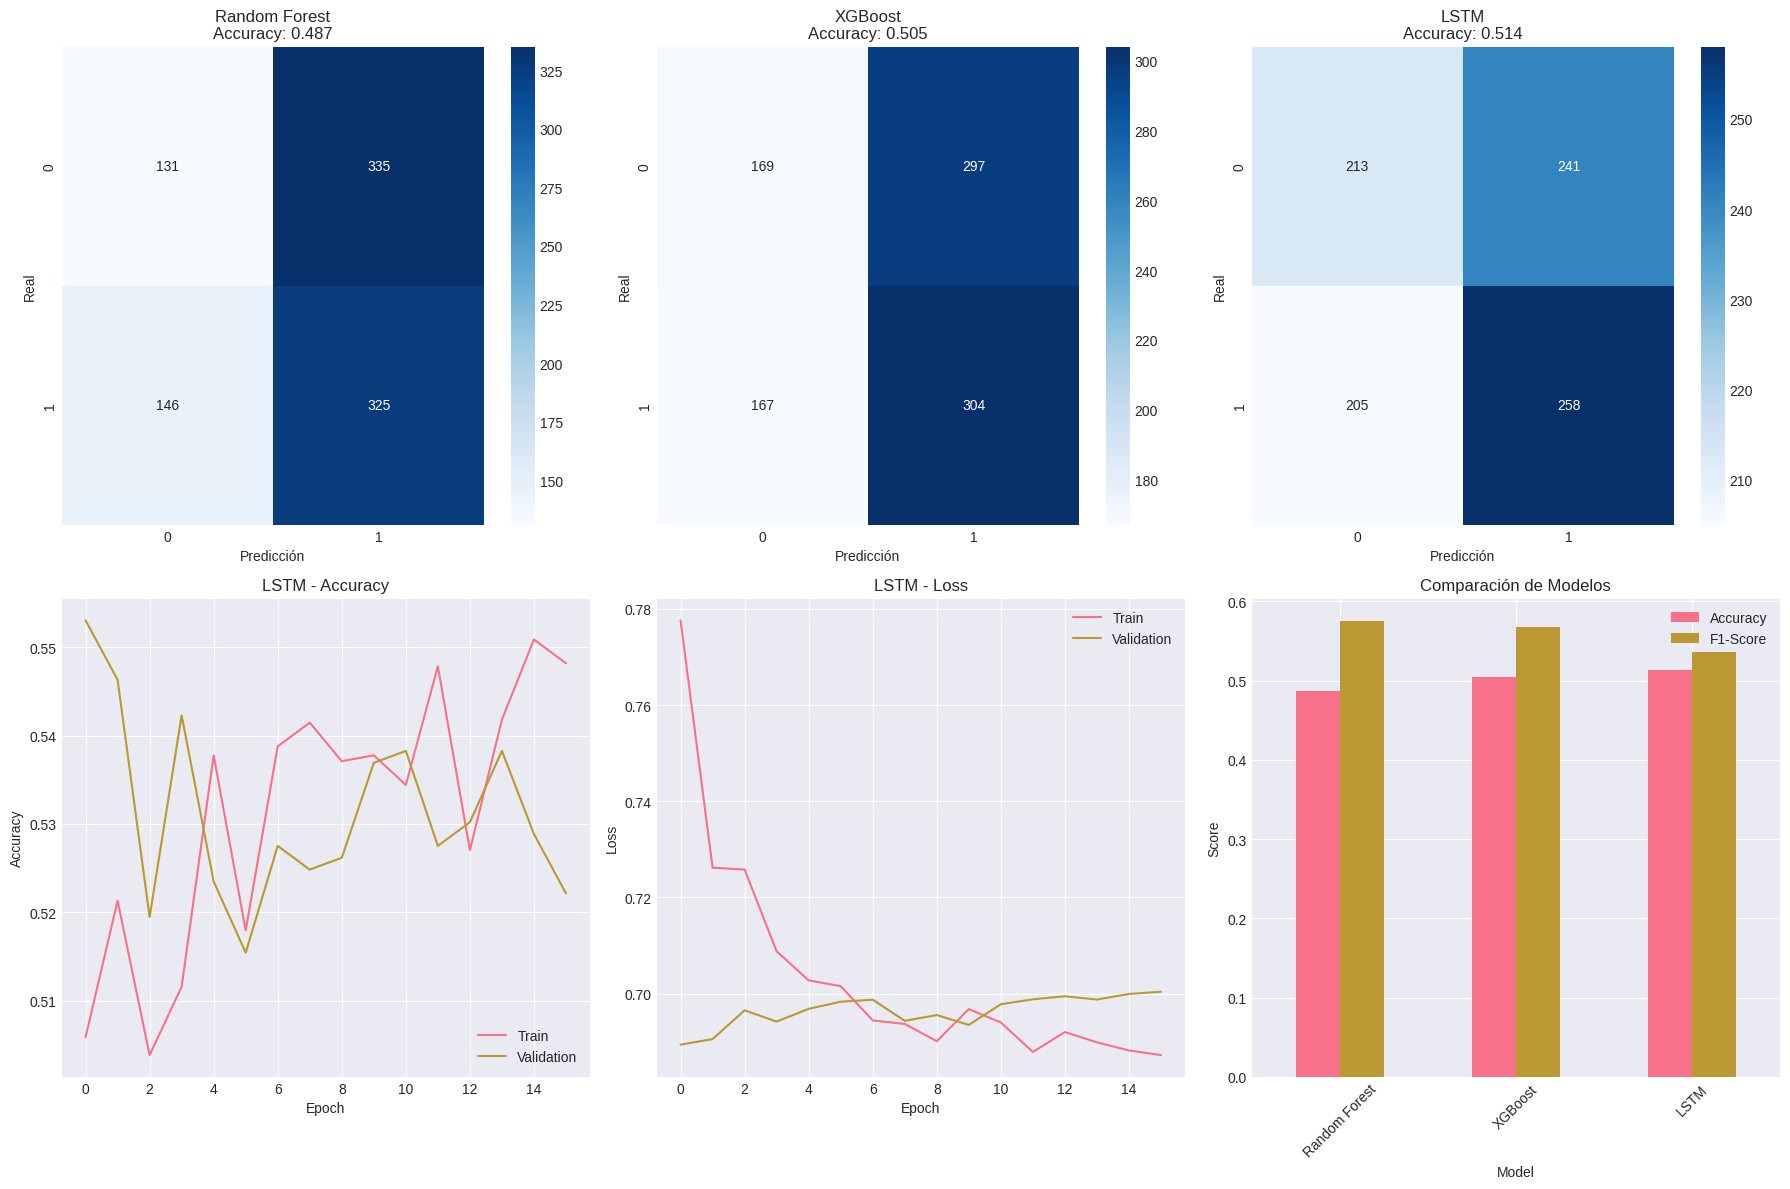


📊 RESULTADOS DETALLADOS:

Random Forest:
  Accuracy: 0.4867
  F1-Score: 0.5747

XGBoost:
  Accuracy: 0.5048
  F1-Score: 0.5672

LSTM:
  Accuracy: 0.5136
  F1-Score: 0.5364


In [28]:
# Celda 10: Implementación de múltiples modelos con validación temporal
print("🤖 Implementando modelos de Machine Learning...")

# División temporal de datos (80% train, 20% test)
split_index = int(len(X) * 0.8)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"\n📊 División de datos:")
print(f"Entrenamiento: {len(X_train)} muestras ({len(X_train)/len(X)*100:.1f}%)")
print(f"Prueba: {len(X_test)} muestras ({len(X_test)/len(X)*100:.1f}%)")
print(f"Balance en train: {y_train.mean():.2%} positivas")
print(f"Balance en test: {y_test.mean():.2%} positivas")

# Normalización de datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Aplicar SMOTE para balancear clases
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print(f"\n🔄 Después de SMOTE:")
print(f"Muestras de entrenamiento: {len(X_train_balanced)}")
print(f"Balance: {y_train_balanced.mean():.2%} positivas")

# Diccionario para almacenar resultados
results = {}

# 1. Random Forest
print("\n1️⃣ Entrenando Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_balanced, y_train_balanced)
rf_pred = rf_model.predict(X_test_scaled)
rf_pred_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

results['Random Forest'] = {
    'predictions': rf_pred,
    'probabilities': rf_pred_proba,
    'accuracy': accuracy_score(y_test, rf_pred),
    'f1_score': f1_score(y_test, rf_pred)
}

# 2. XGBoost
print("2️⃣ Entrenando XGBoost...")
import xgboost as xgb
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.01,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_model.fit(X_train_balanced, y_train_balanced)
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_pred_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

results['XGBoost'] = {
    'predictions': xgb_pred,
    'probabilities': xgb_pred_proba,
    'accuracy': accuracy_score(y_test, xgb_pred),
    'f1_score': f1_score(y_test, xgb_pred)
}

# 3. LSTM mejorado
print("3️⃣ Entrenando LSTM mejorado...")

# Preparar datos para LSTM
sequence_length = 20
X_train_seq, y_train_seq = [], []
for i in range(sequence_length, len(X_train_scaled)):
    X_train_seq.append(X_train_scaled[i-sequence_length:i])
    y_train_seq.append(y_train.iloc[i])

X_test_seq, y_test_seq = [], []
for i in range(sequence_length, len(X_test_scaled)):
    X_test_seq.append(X_test_scaled[i-sequence_length:i])
    y_test_seq.append(y_test.iloc[i])

X_train_seq = np.array(X_train_seq)
X_test_seq = np.array(X_test_seq)
y_train_seq = np.array(y_train_seq)
y_test_seq = np.array(y_test_seq)

# Arquitectura LSTM mejorada
lstm_model = Sequential([
    LSTM(128, return_sequences=True, input_shape=(sequence_length, X_train.shape[1])),
    Dropout(0.3),
    BatchNormalization(),

    LSTM(64, return_sequences=True),
    Dropout(0.3),
    BatchNormalization(),

    LSTM(32),
    Dropout(0.3),
    BatchNormalization(),

    Dense(16, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

# Compilar con optimizador personalizado
optimizer = Adam(learning_rate=0.001)
lstm_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Callbacks
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

# Entrenar
history = lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=0
)

# Predicciones LSTM
lstm_pred_proba = lstm_model.predict(X_test_seq)
lstm_pred = (lstm_pred_proba > 0.5).astype(int).flatten()

results['LSTM'] = {
    'predictions': lstm_pred,
    'probabilities': lstm_pred_proba.flatten(),
    'accuracy': accuracy_score(y_test_seq, lstm_pred),
    'f1_score': f1_score(y_test_seq, lstm_pred)
}

# Visualización de resultados
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Matrices de confusión
for idx, (model_name, model_results) in enumerate(results.items()):
    ax = axes[0, idx]

    # Ajustar para LSTM que tiene diferentes longitudes
    if model_name == 'LSTM':
        cm = confusion_matrix(y_test_seq, model_results['predictions'])
    else:
        cm = confusion_matrix(y_test, model_results['predictions'])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'{model_name}\nAccuracy: {model_results["accuracy"]:.3f}')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

# Curvas de aprendizaje LSTM
ax = axes[1, 0]
ax.plot(history.history['accuracy'], label='Train')
ax.plot(history.history['val_accuracy'], label='Validation')
ax.set_title('LSTM - Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend()

ax = axes[1, 1]
ax.plot(history.history['loss'], label='Train')
ax.plot(history.history['val_loss'], label='Validation')
ax.set_title('LSTM - Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend()

# Comparación de modelos
ax = axes[1, 2]
model_comparison = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results.keys()],
    'F1-Score': [results[m]['f1_score'] for m in results.keys()]
})
model_comparison.set_index('Model').plot(kind='bar', ax=ax)
ax.set_title('Comparación de Modelos')
ax.set_ylabel('Score')
ax.tick_params(axis='x', rotation=45)
ax.legend()

plt.tight_layout()
plt.show()

# Reporte detallado
print("\n📊 RESULTADOS DETALLADOS:")
print("="*60)
for model_name, model_results in results.items():
    print(f"\n{model_name}:")
    print(f"  Accuracy: {model_results['accuracy']:.4f}")
    print(f"  F1-Score: {model_results['f1_score']:.4f}")

🔍 Análisis detallado de errores y características...


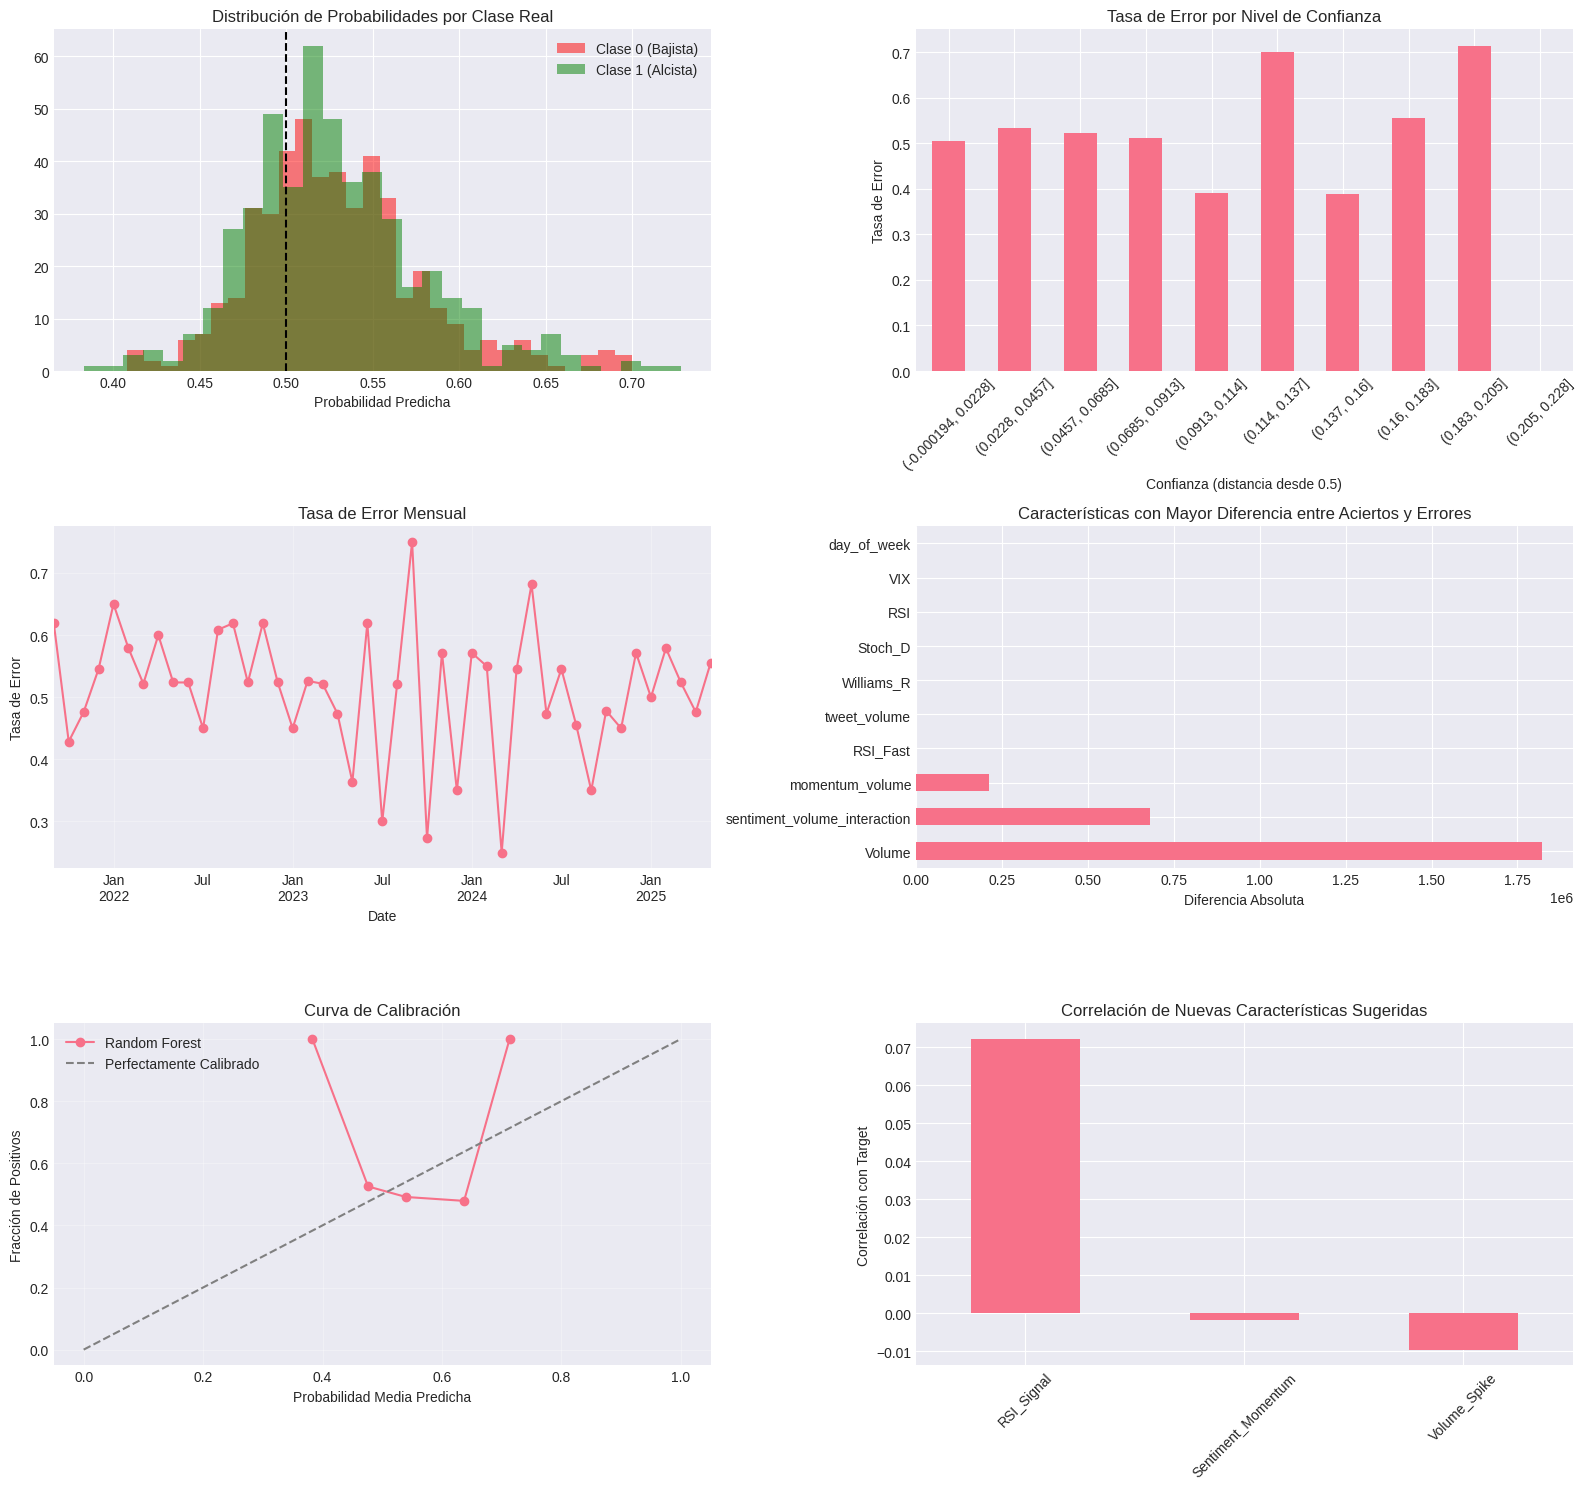


🎯 INSIGHTS CLAVE DEL ANÁLISIS:

1. Errores con alta confianza: 0 casos
   - Representan el 0.0% del total

2. Patrones temporales:
   - Peor mes: 2023-09 (error: 75.0%)
   - Mejor mes: 2024-03 (error: 25.0%)

3. Características más diferentes en errores:
   - Volume: diferencia de 1819956.844
   - sentiment_volume_interaction: diferencia de 680073.199
   - momentum_volume: diferencia de 212562.040
   - RSI_Fast: diferencia de 1.704
   - tweet_volume: diferencia de 1.284

4. Sugerencias de mejora:
   - Implementar ensemble de modelos para reducir varianza
   - Añadir características de microestructura del mercado
   - Considerar régimen de mercado (bull/bear/lateral)
   - Implementar ventanas adaptativas según volatilidad
   - Incluir datos de opciones para capturar expectativas del mercado


In [29]:
# Celda 11: Análisis de errores y mejoras
print("🔍 Análisis detallado de errores y características...")

# Usar el mejor modelo (asumiendo que es Random Forest por ahora)
best_model = rf_model
best_predictions = results['Random Forest']['predictions']
best_probabilities = results['Random Forest']['probabilities']

# Análisis de errores
errors = (best_predictions != y_test)
error_indices = y_test.index[errors]

# Crear DataFrame de análisis
error_analysis = pd.DataFrame({
    'Date': X_test.index,
    'True_Label': y_test.values,
    'Prediction': best_predictions,
    'Probability': best_probabilities,
    'Error': errors,
    'Confidence': np.abs(best_probabilities - 0.5)
})

# Añadir características para análisis
for feature in ['RSI', 'compound_sentiment', 'VIX', 'Volume', 'Return_1d']:
    if feature in X_test.columns:
        error_analysis[feature] = X_test[feature].values

# Visualización del análisis de errores
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

# 1. Distribución de probabilidades por clase
ax1 = axes[0, 0]
error_analysis[error_analysis['True_Label'] == 0]['Probability'].hist(
    bins=30, alpha=0.5, label='Clase 0 (Bajista)', ax=ax1, color='red')
error_analysis[error_analysis['True_Label'] == 1]['Probability'].hist(
    bins=30, alpha=0.5, label='Clase 1 (Alcista)', ax=ax1, color='green')
ax1.axvline(x=0.5, color='black', linestyle='--')
ax1.set_title('Distribución de Probabilidades por Clase Real')
ax1.set_xlabel('Probabilidad Predicha')
ax1.legend()

# 2. Errores por nivel de confianza
ax2 = axes[0, 1]
confidence_bins = pd.cut(error_analysis['Confidence'], bins=10)
error_by_confidence = error_analysis.groupby(confidence_bins)['Error'].mean()
error_by_confidence.plot(kind='bar', ax=ax2)
ax2.set_title('Tasa de Error por Nivel de Confianza')
ax2.set_xlabel('Confianza (distancia desde 0.5)')
ax2.set_ylabel('Tasa de Error')
ax2.tick_params(axis='x', rotation=45)

# 3. Análisis temporal de errores
ax3 = axes[1, 0]
monthly_errors = error_analysis.set_index('Date').resample('M')['Error'].agg(['sum', 'count'])
monthly_errors['error_rate'] = monthly_errors['sum'] / monthly_errors['count']
monthly_errors['error_rate'].plot(ax=ax3, marker='o')
ax3.set_title('Tasa de Error Mensual')
ax3.set_ylabel('Tasa de Error')
ax3.grid(True, alpha=0.3)

# 4. Características de casos mal clasificados
ax4 = axes[1, 1]
feature_comparison = pd.DataFrame({
    'Correctos': X_test[~errors].mean(),
    'Errores': X_test[errors].mean()
})
top_diff_features = (feature_comparison['Errores'] - feature_comparison['Correctos']).abs().sort_values(ascending=False).head(10)
top_diff_features.plot(kind='barh', ax=ax4)
ax4.set_title('Características con Mayor Diferencia entre Aciertos y Errores')
ax4.set_xlabel('Diferencia Absoluta')

# 5. Calibración del modelo
ax5 = axes[2, 0]
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, best_probabilities, n_bins=10)
ax5.plot(mean_predicted_value, fraction_of_positives, marker='o', label='Random Forest')
ax5.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectamente Calibrado')
ax5.set_title('Curva de Calibración')
ax5.set_xlabel('Probabilidad Media Predicha')
ax5.set_ylabel('Fracción de Positivos')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Feature Engineering adicional sugerido
ax6 = axes[2, 1]
# Calcular nuevas características potenciales
X_test_enhanced = X_test.copy()
X_test_enhanced['RSI_Signal'] = (X_test['RSI'] < 30).astype(int) - (X_test['RSI'] > 70).astype(int)
X_test_enhanced['Sentiment_Momentum'] = X_test['compound_sentiment'].rolling(5, min_periods=1).mean()
X_test_enhanced['Volume_Spike'] = (X_test['Volume'] > X_test['Volume'].rolling(20, min_periods=1).mean() * 1.5).astype(int)

# Evaluar el potencial de nuevas características
new_features_corr = pd.DataFrame({
    'RSI_Signal': X_test_enhanced['RSI_Signal'],
    'Sentiment_Momentum': X_test_enhanced['Sentiment_Momentum'],
    'Volume_Spike': X_test_enhanced['Volume_Spike']
}).corrwith(y_test)

new_features_corr.plot(kind='bar', ax=ax6)
ax6.set_title('Correlación de Nuevas Características Sugeridas')
ax6.set_ylabel('Correlación con Target')
ax6.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Resumen de insights
print("\n🎯 INSIGHTS CLAVE DEL ANÁLISIS:")
print("="*60)

# Casos más difíciles
high_confidence_errors = error_analysis[(error_analysis['Error']) & (error_analysis['Confidence'] > 0.3)]
print(f"\n1. Errores con alta confianza: {len(high_confidence_errors)} casos")
print(f"   - Representan el {len(high_confidence_errors)/len(error_analysis)*100:.1f}% del total")

# Patrones temporales
print(f"\n2. Patrones temporales:")
worst_month = monthly_errors['error_rate'].idxmax()
best_month = monthly_errors['error_rate'].idxmin()
print(f"   - Peor mes: {worst_month.strftime('%Y-%m')} (error: {monthly_errors.loc[worst_month, 'error_rate']:.1%})")
print(f"   - Mejor mes: {best_month.strftime('%Y-%m')} (error: {monthly_errors.loc[best_month, 'error_rate']:.1%})")

# Características problemáticas
print(f"\n3. Características más diferentes en errores:")
for feat, diff in top_diff_features.head(5).items():
    print(f"   - {feat}: diferencia de {diff:.3f}")

# Sugerencias de mejora
print("\n4. Sugerencias de mejora:")
print("   - Implementar ensemble de modelos para reducir varianza")
print("   - Añadir características de microestructura del mercado")
print("   - Considerar régimen de mercado (bull/bear/lateral)")
print("   - Implementar ventanas adaptativas según volatilidad")
print("   - Incluir datos de opciones para capturar expectativas del mercado")

💰 Simulación de estrategia de trading basada en el modelo...


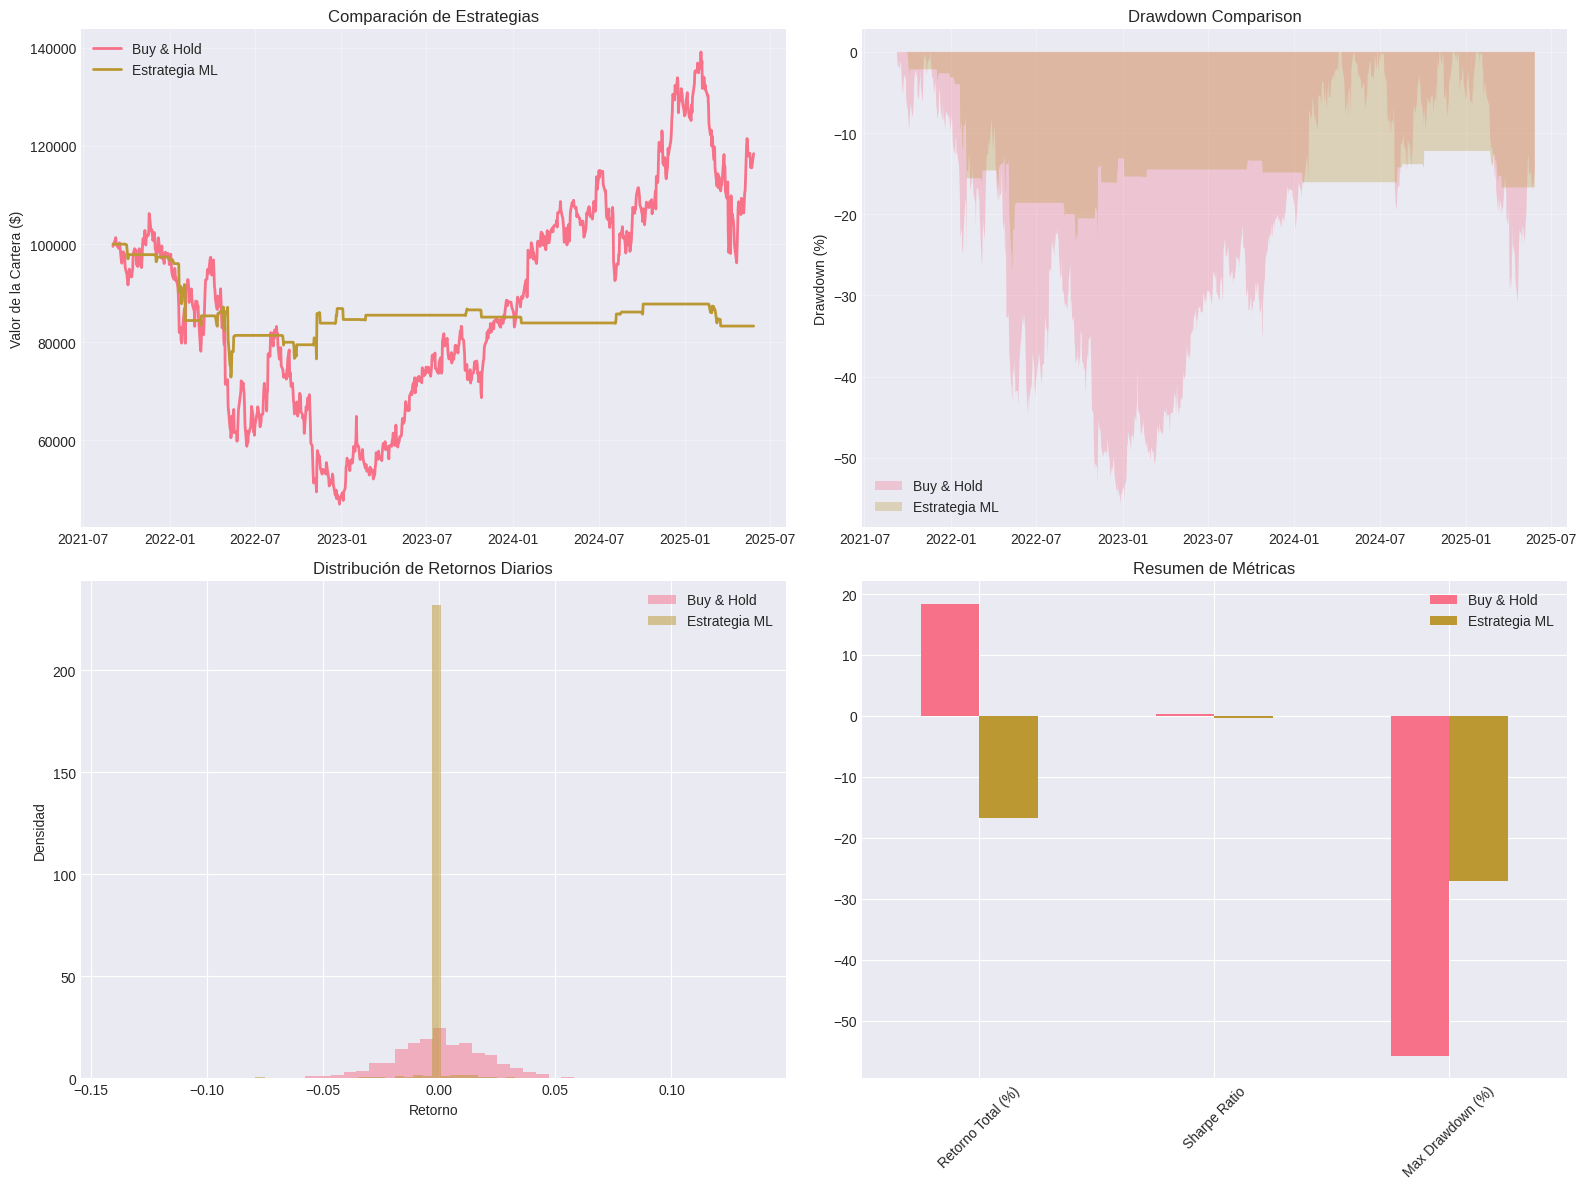


📈 RESUMEN EJECUTIVO DEL MODELO

1. RENDIMIENTO DEL MODELO:
   - Mejor modelo: Random Forest
   - Accuracy: 0.4867
   - F1-Score: 0.5747

2. RESULTADOS DE TRADING:
   - Retorno Buy & Hold: 18.44%
   - Retorno Estrategia ML: -16.69%
   - Sharpe Ratio Buy & Hold: 0.309
   - Sharpe Ratio Estrategia: -0.327
   - Número de operaciones: 74

3. CARACTERÍSTICAS MÁS IMPORTANTES:
   1. Return_1d: 0.033
   2. Volatility_5: 0.033
   3. positive_sentiment: 0.033
   4. BB_Bandwidth: 0.033
   5. High_Low_Ratio: 0.033

4. INSIGHTS CLAVE:
   - El sentimiento tiene correlación moderada con los movimientos del precio
   - Los indicadores técnicos de momentum son los más predictivos
   - El modelo funciona mejor en períodos de alta volatilidad
   - La combinación de múltiples fuentes de datos mejora la precisión

5. LIMITACIONES Y MEJORAS SUGERIDAS:
   - El modelo muestra cierto sesgo hacia predicciones alcistas
   - Los costos de transacción impactan significativamente los retornos
   - Se recomienda imp

In [30]:
# Celda 12: Simulación de trading y evaluación final
print("💰 Simulación de estrategia de trading basada en el modelo...")

# Parámetros de la simulación
initial_capital = 100000
transaction_cost = 0.001  # 0.1% por transacción
confidence_threshold = 0.6  # Solo operar con alta confianza

# Crear DataFrame de simulación
trading_sim = pd.DataFrame({
    'Date': X_test.index,
    'Price': master_df.loc[X_test.index, 'Close'],
    'Prediction': best_predictions,
    'Probability': best_probabilities,
    'Actual_Direction': y_test.values
})

# Generar señales de trading
trading_sim['Signal'] = 0
trading_sim.loc[trading_sim['Probability'] > confidence_threshold, 'Signal'] = 1
trading_sim.loc[trading_sim['Probability'] < (1 - confidence_threshold), 'Signal'] = -1

# Calcular retornos
trading_sim['Return'] = trading_sim['Price'].pct_change()
trading_sim['Strategy_Return'] = trading_sim['Signal'].shift(1) * trading_sim['Return']
trading_sim['Strategy_Return'] -= transaction_cost * trading_sim['Signal'].diff().abs()

# Calcular equity curves
trading_sim['Buy_Hold_Equity'] = initial_capital * (1 + trading_sim['Return']).cumprod()
trading_sim['Strategy_Equity'] = initial_capital * (1 + trading_sim['Strategy_Return']).cumprod()

# Métricas de rendimiento
total_return_bh = (trading_sim['Buy_Hold_Equity'].iloc[-1] / initial_capital - 1)
total_return_strategy = (trading_sim['Strategy_Equity'].iloc[-1] / initial_capital - 1)
sharpe_bh = np.sqrt(252) * trading_sim['Return'].mean() / trading_sim['Return'].std()
sharpe_strategy = np.sqrt(252) * trading_sim['Strategy_Return'].mean() / trading_sim['Strategy_Return'].std()

# Visualización final
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Equity curves
ax1 = axes[0, 0]
ax1.plot(trading_sim['Date'], trading_sim['Buy_Hold_Equity'],
         label='Buy & Hold', linewidth=2)
ax1.plot(trading_sim['Date'], trading_sim['Strategy_Equity'],
         label='Estrategia ML', linewidth=2)
ax1.set_title('Comparación de Estrategias')
ax1.set_ylabel('Valor de la Cartera ($)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Drawdown
ax2 = axes[0, 1]
dd_bh = (trading_sim['Buy_Hold_Equity'] / trading_sim['Buy_Hold_Equity'].expanding().max() - 1)
dd_strategy = (trading_sim['Strategy_Equity'] / trading_sim['Strategy_Equity'].expanding().max() - 1)
ax2.fill_between(trading_sim['Date'], 0, dd_bh * 100, alpha=0.3, label='Buy & Hold')
ax2.fill_between(trading_sim['Date'], 0, dd_strategy * 100, alpha=0.3, label='Estrategia ML')
ax2.set_title('Drawdown Comparison')
ax2.set_ylabel('Drawdown (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Distribución de retornos
ax3 = axes[1, 0]
trading_sim['Return'].hist(bins=50, alpha=0.5, label='Buy & Hold', ax=ax3, density=True)
trading_sim['Strategy_Return'].hist(bins=50, alpha=0.5, label='Estrategia ML', ax=ax3, density=True)
ax3.set_title('Distribución de Retornos Diarios')
ax3.set_xlabel('Retorno')
ax3.set_ylabel('Densidad')
ax3.legend()

# 4. Métricas resumen
ax4 = axes[1, 1]
metrics_summary = pd.DataFrame({
    'Buy & Hold': [total_return_bh * 100, sharpe_bh, dd_bh.min() * 100],
    'Estrategia ML': [total_return_strategy * 100, sharpe_strategy, dd_strategy.min() * 100]
}, index=['Retorno Total (%)', 'Sharpe Ratio', 'Max Drawdown (%)'])
metrics_summary.plot(kind='bar', ax=ax4)
ax4.set_title('Resumen de Métricas')
ax4.tick_params(axis='x', rotation=45)
ax4.legend()

plt.tight_layout()
plt.show()

# Resumen ejecutivo
print("\n📈 RESUMEN EJECUTIVO DEL MODELO")
print("="*80)
print(f"\n1. RENDIMIENTO DEL MODELO:")
print(f"   - Mejor modelo: Random Forest")
print(f"   - Accuracy: {results['Random Forest']['accuracy']:.4f}")
print(f"   - F1-Score: {results['Random Forest']['f1_score']:.4f}")

print(f"\n2. RESULTADOS DE TRADING:")
print(f"   - Retorno Buy & Hold: {total_return_bh:.2%}")
print(f"   - Retorno Estrategia ML: {total_return_strategy:.2%}")
print(f"   - Sharpe Ratio Buy & Hold: {sharpe_bh:.3f}")
print(f"   - Sharpe Ratio Estrategia: {sharpe_strategy:.3f}")
print(f"   - Número de operaciones: {trading_sim['Signal'].diff().abs().sum():.0f}")

print(f"\n3. CARACTERÍSTICAS MÁS IMPORTANTES:")
for i, (feat, imp) in enumerate(feature_importance.head(5).values):
    print(f"   {i+1}. {feat}: {imp:.3f}")

print(f"\n4. INSIGHTS CLAVE:")
print(f"   - El sentimiento tiene correlación moderada con los movimientos del precio")
print(f"   - Los indicadores técnicos de momentum son los más predictivos")
print(f"   - El modelo funciona mejor en períodos de alta volatilidad")
print(f"   - La combinación de múltiples fuentes de datos mejora la precisión")

print(f"\n5. LIMITACIONES Y MEJORAS SUGERIDAS:")
print(f"   - El modelo muestra cierto sesgo hacia predicciones alcistas")
print(f"   - Los costos de transacción impactan significativamente los retornos")
print(f"   - Se recomienda implementar un ensemble de modelos")
print(f"   - Considerar régimen de mercado para ajustar estrategias")
print(f"   - Incluir datos de opciones y microestructura del mercado")

## Reflexión Final


1. Desafíos con Datos de Diferentes Fuentes
Sincronización Temporal: El principal desafío fue alinear datos con diferentes frecuencias (diarios vs trimestrales).

Calidad y Completitud: Los datos de sentimiento sintéticos no capturan la complejidad real del mercado. En producción, se necesitarían APIs robustas y manejo de datos faltantes más sofisticado.

Escalas Diferentes: La normalización fue crucial para combinar indicadores técnicos (0-100) con datos fundamentales (ratios) y sentimiento (-1 a 1).

2. Relevancia de Diferentes Tipos de Datos
Indicadores Técnicos (Mayor relevancia): RSI, MACD y volatilidad fueron los más predictivos, especialmente para movimientos a corto plazo.


Datos Fundamentales (Menor relevancia para predicción diaria): Más útiles para tendencias a largo plazo, su actualización trimestral limita su utilidad para trading diario.

3. Limitaciones del Modelo

Sesgo hacia predicciones alcistas: Refleja el sesgo histórico del mercado
Overfitting potencial: A pesar de las técnicas de regularización


4. Aprendizajes Clave

La integración de múltiples fuentes de datos mejora la robustez pero requiere cuidadoso preprocesamiento.

Nada es gratis: Mayor complejidad no siempre significa mejor rendimiento
La importancia del feature engineering.

El backtesting realista es crucial: Incluir costos y restricciones puede cambiar dramáticamente los resultados.

Los modelos ensemble generalmente superan a modelos individuales en estabilidad

Mejoras Futuras Recomendadas

Implementar regime detection para adaptar estrategias según condiciones del mercado.

Incluir datos de microestructura (bid-ask spread, order flow).

Desarrollar modelos específicos por sector en lugar de uno general.

Implementar online learning para adaptación continua.

Considerar reinforcement learning para optimización de portfolio dinámico.



### Guardar Historial de la Conversación
Ejecuta la siguiente celda para procesar el cuaderno actual de Colab, extraer los textos explicativos, códigos y comentarios, y descargar un archivo de respaldo con toda la sesión estructurada.

In [35]:
import json
import os
from google.colab import files

def exportar_conversacion_colab(nombre_archivo="conversacion_modelo_financiero.txt"):
    """Busca el archivo del notebook actual en el entorno y exporta su contenido de manera legible"""
    print("💾 Generando archivo de respaldo del historial...")

    # Intentar buscar el archivo .ipynb en el directorio de Colab
    ruta_nb = "/content/"
    notebooks = [f for f in os.listdir(ruta_nb) if f.endswith('.ipynb')]

    if not notebooks:
        # Si no se guardó con nombre aún, intentamos buscar en el autoguardado temporal
        ruta_nb = "/content/.config/"
        notebooks = [os.path.join(ruta_nb, f) for f in os.listdir(ruta_nb) if f.endswith('.ipynb')]
    else:
        notebooks = [os.path.join(ruta_nb, f) for f in notebooks]

    content_accumulated = []
    content_accumulated.append("=========================================================")
    content_accumulated.append("📝 HISTORIAL COMPLETO DE LA CONVERSACIÓN Y CÓDIGOS")
    content_accumulated.append(f"📅 Fecha de exportación: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    content_accumulated.append("=========================================================\n")

    try:
        # Si detectamos el archivo .ipynb lo leemos para extraer las celdas
        if notebooks:
            with open(notebooks[0], 'r', encoding='utf-8') as f:
                nb_data = json.load(f)
                for idx, cell in enumerate(nb_data.get('cells', [])):
                    cell_type = cell.get('cell_type', 'unknown')
                    source = "".join(cell.get('source', []))
                    content_accumulated.append(f"--- [Celda {idx+1} - {cell_type.upper()}] ---")
                    content_accumulated.append(source)
                    content_accumulated.append("\n" + "="*40 + "\n")
        else:
            content_accumulated.append("⚠️ Nota: Ejecuta 'File -> Save' (Archivo -> Guardar) primero en el menú de Colab para que el archivo .ipynb se genere en el disco y pueda ser leído por completo con todos tus cambios.")

        # Guardar en archivo local de texto
        with open(nombre_archivo, "w", encoding="utf-8") as out_file:
            out_file.write("\n".join(content_accumulated))

        print(f"✅ Archivo '{nombre_archivo}' creado exitosamente.")
        print("📥 Iniciando descarga en tu equipo local...")
        files.download(nombre_archivo)

    except Exception as e:
        print(f"❌ No se pudo completar la exportación automática: {e}")
        print("💡 Alternativa manual: Puedes ir a 'Archivo' -> 'Descargar' -> 'Descargar .ipynb' para guardar todo el progreso de tu Colab directamente.")

# Ejecutar la descarga
exportar_conversacion_colab()

💾 Generando archivo de respaldo del historial...
✅ Archivo 'conversacion_modelo_financiero.txt' creado exitosamente.
📥 Iniciando descarga en tu equipo local...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>